# 🍯 Gümüşhane Pestil & Köme Satış Verisi — Adım Adım Veri Hazırlama

**Uygulamalı Ders Defteri (Jupyter Notebook)**

Bu defterde bir aile işletmesinin **üç farklı sistemden gelen dağınık verisini** adım adım temizleyip, birleştirip, analize hazır **tek bir veri setine** dönüştüreceğiz.

İşletme sahibinin soruları:
1. Hangi **ilçeden**, hangi **üründen**, hangi **ayda** ne kadar satıyoruz?
2. **Gurbetçi** müşterilerimiz yerel müşterilerden farklı mı davranıyor?
3. **Kargo mesafesi** memnuniyeti etkiliyor mu?

---

### 📌 Bu defter nasıl kullanılır?

| Simge | Anlamı |
|---|---|
| 📖 | **Kavram** – kısa teorik bilgi |
| 🎯 | **Amaç** – bu adımda ne yapacağız |
| ▶️ | **Örnek kod** – çalıştırın ve çıktıyı inceleyin |
| 🔍 | **Ne gördük?** – çıktının yorumu |
| ✍️ | **Sıra sende** – kendiniz deneyin (kodun içindeki `# TODO` satırlarını doldurun) |
| ✅ | **Çözüm** – sizin denemenizden sonra çalıştırın; sonraki adımlar bu hücreye dayanır |
| ⚠️ | **Dikkat** – sık yapılan hatalar |

**Kurallar:**
- Hücreleri **yukarıdan aşağıya, sırayla** çalıştırın (`Shift + Enter`).
- Bir hata alırsanız: menüden **Kernel → Restart & Run All** ile baştan çalıştırın.
- ✍️ hücrelerinde hata yapmanız sorun değil — ✅ çözüm hücresi akışı düzeltir.
- Her adımda `kaydet(...)` fonksiyonu **kaç satırın etkilendiğini** rapora yazar. Defterin sonunda bu rapor hazır bir tablo olarak çıkar.

### 🗺️ Yol Haritası
0. Hazırlık ve veriyi okuma
1. Değişken tipleri
2. Veri temizleme (eksik, tutarsız, gürültülü veri, tekrarlar)
3. Veri birleştirme (şema, varlık eşleştirme, değer karmaşıklığı, fazlalık)
4. Veri indirgeme (veri küpü, boyut indirgeme, sıkıştırma, histogram & örnekleme)
5. Veri dönüştürme (normalleştirme, genelleme, özellik oluşturma)
6. İşletmenin sorularını cevaplama
7. Rapor ve teslim

---
# 0. Hazırlık

## 0.1 Kütüphaneler

🎯 Kullanacağımız kütüphaneleri yükleyelim.
- `pandas` → tablo (DataFrame) işlemleri
- `numpy` → sayısal işlemler
- `matplotlib` → grafikler
- `openpyxl` → Excel dosyası okuma (pandas arka planda kullanır)
- `pyarrow` → Parquet formatı (Bölüm 4'te; yoksa o adım atlanır)

⚠️ Eksik kütüphane hatası alırsanız bir hücreye `!pip install openpyxl pyarrow` yazıp çalıştırın.

In [1]:
import re
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams["figure.figsize"] = (9, 4)

print("pandas sürümü:", pd.__version__)

pandas sürümü: 3.0.2


## 0.2 Veri dosyalarını bulma

Veri dosyaları bu defterle **aynı klasörde** olmalı. İki seçenek:
- `gumushane_pestil_kome_veriseti.zip` dosyasını defterin yanına koyun (aşağıdaki kod kendisi açar), **ya da**
- zip'i açıp `gumushane_pestil_kome_veriseti/` klasörünü defterin yanına koyun.

💡 *Google Colab kullanıyorsanız:* sol menüdeki 📁 simgesinden zip dosyasını yükleyin.

In [2]:
KLASOR = "gumushane_pestil_kome_veriseti"
adaylar = [Path(KLASOR), Path("."), Path("veri") / KLASOR]

def veri_var_mi(p):
    return (p / "A_dukkan_kasa_satislari.csv").exists()

# Klasör yoksa ama zip varsa, zip'i aç
if not any(veri_var_mi(p) for p in adaylar) and Path(KLASOR + ".zip").exists():
    zipfile.ZipFile(KLASOR + ".zip").extractall(".")
    print("Zip dosyası açıldı.")

VERI = next((p for p in adaylar if veri_var_mi(p)), None)
assert VERI is not None, "Veri dosyaları bulunamadı! Zip dosyasını defterin yanına koyun."
print("Veri klasörü:", VERI.resolve())
print([f.name for f in sorted(VERI.iterdir())])

Veri klasörü: C:\Users\kahra\OneDrive\Documents\GitHub\YBS-DataMining\hafta2\gumushane_pestil_kome_veriseti
['.ipynb_checkpoints', 'A_dukkan_kasa_satislari.csv', 'B_eticaret_siparisleri.xlsx', 'C_uretici_kayitlari.csv', 'D_ilce_referans_tablosu.csv', 'gumushane_veri_hazirlama_uygulamasi.ipynb', 'readme.md']


## 0.3 Yardımcı fonksiyonlar

📖 Türkçe metinlerde iki büyük tuzak vardır:
1. Python'un `.lower()` fonksiyonu `"I"` harfini `"i"` yapar (Türkçede `"ı"` olmalı) ve `"İ"` harfini `"i̇"` (noktalı + fazladan bir işaret) yapar.
2. Aynı kelime `Kürtün`, `Kurtun`, `KÜRTÜN`, `Kürtun` gibi yazılabilir.

Bu yüzden her metni karşılaştırmadan önce **ortak bir anahtara** çeviren küçük fonksiyonlar yazıyoruz:

| Fonksiyon | Ne yapar | Örnek |
|---|---|---|
| `tr_kucuk(x)` | Türkçe kurallarına uygun küçük harf | `"KELKİT"` → `"kelkit"` |
| `anahtar(x)` | küçük harf + Türkçe karakterleri sadeleştir + boşlukları temizle | `"Kürtun "` → `"kurtun"` |
| `tr_baslik(x)` | Her kelimenin ilk harfi büyük | `"osman ÇETİN"` → `"Osman Çetin"` |
| `tr_sayi(x)` | Türkçe sayıyı (`1.454,20`) sayıya çevir | `"3.454,20"` → `3454.2` |
| `kaydet(...)` | Yapılan işlemi ve etkilenen satır sayısını rapora ekler | |

▶️ Hücreyi çalıştırın ve alttaki küçük testlere bakın.

In [4]:
TR_ASCII = str.maketrans("çğıöşüâîû", "cgiosuaiu")

def tr_kucuk(x):
    # Türkçe uyumlu küçük harf
    if pd.isna(x):
        return x
    x = str(x).replace("I", "ı").replace("İ", "i").lower()
    return x.replace("\u0307", "")          # 'i̇' içindeki fazladan noktayı sil

def anahtar(x):
    # Karşılaştırma anahtarı: küçük harf, Türkçe karakter yok, tek boşluk
    if pd.isna(x):
        return x
    x = tr_kucuk(x).translate(TR_ASCII)
    return re.sub(r"\s+", " ", x).strip()

def tr_baslik(x):
    # 'osman ÇETİN' -> 'Osman Çetin'
    if pd.isna(x):
        return x
    buyuk = {"i": "İ", "ı": "I"}
    kelimeler = tr_kucuk(x).split()
    return " ".join(buyuk.get(k[0], k[0].upper()) + k[1:] for k in kelimeler)

def tr_sayi(seri):
    # '3.454,20' -> 3454.20  (binlik ayırıcı nokta, ondalık virgül)
    s = seri.astype(str).str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    return pd.to_numeric(s, errors="coerce").astype("float64")

# --- İşlem raporu ---
rapor = []
def kaydet(veri, adim, islem, n, birim="satır"):
    rapor.append({"veri": veri, "adım": adim, "işlem": islem, "etkilenen": int(n), "birim": birim})
    print(f"✔ [{veri}] {islem}  →  {int(n)} {birim}")

# Küçük testler
print(anahtar("  KÜRTÜN "), "|", anahtar("Kelkıt"), "|", anahtar("ÇOK İYİ"), "|", anahtar("çok i̇yi"))
print(tr_baslik("osman ÇETİN"), "|", tr_baslik("HÜLYA BULUT"))
print(tr_sayi(pd.Series(["3.454,20", "275,00", "1031,00"])).tolist())

kurtun | kelkit | cok iyi | cok iyi
Osman Çetin | Hülya Bulut
[3454.2, 275.0, 1031.0]


🔍 `"ÇOK İYİ"` ve `"çok i̇yi"` aynı anahtara (`cok iyi`) dönüştü. Bundan sonra **tüm yazım farklılıklarını bu yöntemle** tek biçime indireceğiz: önce `anahtar()` uygula, sonra bir sözlükle (`dict`) doğru yazıma eşle.

## 0.4 Veriyi okuma

📖 Dosyaların özellikleri (readme'den):

| Dosya | Ayırıcı | Ondalık | Not |
|---|---|---|---|
| `A_dukkan_kasa_satislari.csv` | `;` | `,` | Türkçe Excel çıktısı |
| `B_eticaret_siparisleri.xlsx` | – | – | 2 sayfa: `orders` ve `metadata` |
| `C_uretici_kayitlari.csv` | `;` | `,` | |
| `D_ilce_referans_tablosu.csv` | `,` | `.` | **Temiz** referans tablo |

⚠️ **Önemli taktik:** A ve C'yi `dtype=str` ve `keep_default_na=False` ile okuyoruz. Böylece pandas hiçbir değeri kendi kafasına göre "eksik" ya da "sayı" yapmaz; **ham hali** görürüz. Eksik veri kodlarını kendimiz keşfedeceğiz.

In [5]:
A_ham = pd.read_csv(VERI / "A_dukkan_kasa_satislari.csv", sep=";", dtype=str,
                    keep_default_na=False, encoding="utf-8-sig")
B_ham = pd.read_excel(VERI / "B_eticaret_siparisleri.xlsx", sheet_name="orders")
B_meta = pd.read_excel(VERI / "B_eticaret_siparisleri.xlsx", sheet_name="metadata")
C_ham = pd.read_csv(VERI / "C_uretici_kayitlari.csv", sep=";", dtype=str,
                    keep_default_na=False, encoding="utf-8-sig")
D = pd.read_csv(VERI / "D_ilce_referans_tablosu.csv", encoding="utf-8-sig")

for ad, df in [("A", A_ham), ("B", B_ham), ("C", C_ham), ("D", D)]:
    print(f"{ad}: {df.shape[0]:>5} satır, {df.shape[1]:>2} sütun")

A:  2732 satır, 20 sütun
B:  2001 satır, 23 sütun
C:    26 satır, 11 sütun
D:     6 satır,  6 sütun


In [6]:
A_ham.head()

,fis_no,satir_no,tarih,sube,musteri_no,ad_soyad,cinsiyet,yas,dogum_yili,ilce,urun,adet,birim_fiyat_TL,tutar_TL,kdv_dahil_tutar_TL,odeme,memnuniyet,uyelik,depo_sicaklik_C,notlar
0,100003,1,2024-10-05,Gümüşhane Çarşı,M-00426,Osman Çetin,E,69,1955,KÖSE,pekmez,2,"275,00","550,00","555,50",Nakit,bilinmiyor,Gümüş,"17,6",
1,100003,2,05.10.2024,Gümüşhane Çarşı,M-00426,OSMAN ÇETİN,E,69,1960,Köse,Cevizli Pestil,1,"300,00","300,00","303,00",Nakit,,Gümüş,"16,9",
2,100003,3,05.10.2024 19:03,Gümüşhane Çarşı,M-00426,Osman Çetin,E,69,1955,Kose,Yayla Balı,4,"855,00","3420,00","3.454,20",NAKİT,?,gümüş,"15,0",
3,100004,1,2024-10-26,Gümüşhane Çarşı,796,Zeynep Yıldız,K,63,1961,Merkez,Cevizli Pestil,5,"305,00","1525,00","1540,25",Nakit,-,Bronz,"13,4",
4,100007,1,10.04.2024,Gümüşhane Çarşı,M-00615,Hülya Bulut,K,31,1993,Kürtün,Dut Pestili,1,"205,00","205,00","207,05",NAKİT,4,Bronz,"13,5",


In [7]:
B_ham.head()

,order_id,order_date,customer_id,customer_name,gender,birth_date,shipping_city,shipping_district,product_sku,product_name,quantity,weight_g,amount_kurus,shipping_fee_kurus,free_shipping,distance_km,delivery_days,rating_10,membership,producer_code,campaign_code,platform,export_batch
0,ORD-2025-000001,2025-08-03 18:35:36,gmh5412,OSMAN KESKİN,M,1976-02-24,Kocaeli,NaN,PKM-DUT-1000,Dut Pekmezi 1 kg,2,2000.0,79717,8726,Hayır,939,2.0,NaN,NaN,U-024,NaN,PazarYeri,EXP-2025-10-01
1,ORD-2025-000002,2025-06-03 20:14:36,GMH-2588,YUSUF ÇETİN,M,1952-05-24,Ankara,NaN,KDT-500,Kuru Dut 500 g,5,2500.0,108921,0,TRUE,743,2.0,0.0,Bronze,U-017,GURBET20,PazarYeri,EXP-2025-10-01
2,ORD-2025-000003,2025-07-12 06:25:46,GMH-6249,BÜŞRA YILMAZ,F,1968-03-21,Almanya,NaN,PKM-DUT-1000,Dut Pekmezi 1 kg,1,1000.0,31003,78694,FALSE,2873,6.0,NaN,Bronze,U-002,GURBET20,PazarYeri,EXP-2025-10-01
3,ORD-2025-000004,2025-09-24 09:49:32,GMH-6639,Hulya Karatas,F,1992-03-14,Gümüşhane,NaN,PST-CEV-500,Cevizli Pestil 500 g,3,1500.0,139281,0,TRUE,4,2.0,NaN,Bronze,U-010,NaN,PazarYeri,EXP-2025-10-01
4,ORD-2024-000005,2024-07-13 19:10:51,GMH-7990,ERCAN KOÇ,M,NaN,İstanbul,NaN,PST-DUT-500,Dut Pestili 500 g,1,NaN,22940,6746,FALSE,1011,3.0,NaN,Silver,U-006,NaN,PazarYeri,EXP-2025-10-01


⚠️ B dosyasının `metadata` sayfasını **mutlaka okuyun**. Sütunların birimleri ve özel kodları burada yazıyor (ör. tutar *kuruş* cinsinden, `rating_10` için `0 = puan yok`, `1900-01-01 = doğum tarihi verilmemiş`).

In [8]:
B_meta

,column,description
0,order_id,Platform order number
1,order_date,"Order timestamp (export tool v1 / v2, see notes)"
2,customer_id,Platform customer no. NOT the same as shop cus...
3,customer_name,As typed by customer
4,gender,M / F. Legacy accounts (before migration): 1 =...
5,birth_date,YYYY-MM-DD; 1900-01-01 = not provided
6,shipping_city,Free text
7,shipping_district,Only required for Gümüşhane deliveries
8,product_sku,Stock keeping unit
9,quantity,Units


In [9]:
C_ham

,uretici_kodu,uretici_adi,ilce,rakim_m,organik_sertifika,kurulus_yili,yillik_kapasite,kalite_sinifi,ort_depo_sicakligi,urun_kodlari,telefon
0,U01,Kayalar Pestil,Köse,1492,,1996,"47,0",a,"9,4","KDT-500,KOM-FIN-500,KRM-1500,KSB-MAR-450",0456 245 91 77
1,U02,Demiroğlu Köme,Merkez,1420,Yok,2006,"4,1 ton",C,"11,8","KOM-CEV-500,KRM-1500,PKM-DUT-1000,PST-CEV-500",0456 208 10 92
2,U03,Harşit Kıyısı Gıda,Şiran,1657,VAR,2001,"58,6 ton",B,"8,8","KDT-500,KOM-CEV-500,KSB-MAR-450,PKM-DUT-1000",0456 252 16 70
3,U04,Yukarı Bağlar Pestilcilik,Şiran,12000,Hayır,1987,"53,2",B,"8,7","KDT-500,KOM-CEV-500,KOM-FIN-500,KSB-MAR-450",0456 208 92 42
4,U05,Akyol Dut Ürünleri,Kürtün,1058,1,1981,"34,1 ton",2. Sınıf,"16,0","KSB-MAR-450,PKM-DUT-1000,PST-DUT-500",0456 297 49 40
5,U06,Kelkit Ovası Kooperatifi,Kelkit,1420,Yok,2018,5400 kg,C,"9,3","KOM-CEV-500,KOM-FIN-500,PST-DUT-500",0456 285 97 48
6,U07,Çiftçioğlu Pekmez,Merkez,1160,Evet,2001,"16,7",B,"54,5","KDT-500,KOM-FIN-500,KSB-MAR-450",0456 243 32 78
7,U08,Yayla Yolu Arıcılık,Kelkit,1280,Hayır,1990,6100 kg,B,"8,8",BAL-850,0456 246 91 45
8,U09,Bağbaşı Kadın Kooperatifi,Torul,936,,2031,15600 kg,C,"15,8","KDT-500,KOM-FIN-500,KSB-MAR-450",0456 262 52 69
9,U10,Gökçe Pestil Evi,Merkez,1432,0,2012,"47,8 ton",B,"9,0","KDT-500,KOM-FIN-500,KRM-1500,PKM-DUT-1000,PST-...",0456 262 64 92


In [10]:
D   # Referans tablo – temiz kabul ediliyor

,ilce,il,bolge,merkeze_uzaklik_km,yaklasik_rakim_m,il_plaka
0,Merkez,Gümüşhane,Harşit Vadisi,0,1210,29
1,Torul,Gümüşhane,Harşit Vadisi,30,950,29
2,Kürtün,Gümüşhane,Harşit Vadisi,65,1000,29
3,Kelkit,Gümüşhane,Kelkit Havzası,80,1400,29
4,Köse,Gümüşhane,Kelkit Havzası,60,1450,29
5,Şiran,Gümüşhane,Kelkit Havzası,100,1400,29


🔍 Daha ilk bakışta bile sorunlar görünüyor:
- A'da aynı fişte tarih `2024-10-05`, `05.10.2024` ve `05.10.2024 19:03` olarak üç farklı biçimde yazılmış.
- A'da aynı müşterinin adı `Osman Çetin` / `OSMAN ÇETİN`, ilçesi `KÖSE` / `Köse` / `Kose`.
- B'de tarih bazen `03/13/2024` (Amerikan formatı) bazen `45309` gibi bir sayı (Excel tarih numarası).
- C'de kapasite `47,0`, `4,1 ton`, `5400 kg` gibi farklı birimlerde.

Hepsini sırayla çözeceğiz. Önce sütunları tanıyalım.

---
# 1. Değişken Tipleri

📖 **Ölçek türleri:**

| Tür | Açıklama | Anlamlı işlemler | Örnek |
|---|---|---|---|
| **İsimsel (nominal)** | Sadece kategori, sıra yok | `=`, `≠`, sayma, mod | ilçe, ürün, ödeme türü |
| **İkili (binary)** | Sadece 2 değer | sayma, oran | cinsiyet, ücretsiz kargo |
| **Sıra gösteren (ordinal)** | Kategoriler arasında sıra var, aralıklar eşit değil | `<`, `>`, medyan | memnuniyet (Kötü < Orta < İyi), üyelik (Bronz < Gümüş < Altın) |
| **Tamsayılı (discrete)** | Sayılabilir tam sayılar | toplama, ortalama | adet, teslim günü |
| **Aralıklı (interval)** | Farklar anlamlı, **sıfır keyfi** → oran anlamsız | `+`, `−`, ortalama | sıcaklık (°C), tarih, rakım |
| **Oranlı (ratio)** | **Gerçek sıfır** var → oran anlamlı | `×`, `÷` dahil hepsi | tutar, ağırlık, mesafe |

### Aralıklı mı, oranlı mı? Küçük bir deney 🔬
"20 °C, 10 °C'nin iki katı sıcak mıdır?" Aynı sıcaklıkları Fahrenheit'a çevirip oranlara bakalım:

In [12]:
c1, c2 = 10, 20
f1, f2 = c1 * 9/5 + 32, c2 * 9/5 + 32
print(f"Celsius   : {c2}/{c1} = {c2/c1:.2f}")
print(f"Fahrenheit: {f2:.0f}/{f1:.0f} = {f2/f1:.2f}   <- aynı sıcaklıklar, farklı oran!")

g1, g2 = 500, 1000                        # gram
print(f"\nGram      : {g2}/{g1} = {g2/g1:.2f}")
print(f"Kilogram  : {g2/1000}/{g1/1000} = {(g2/1000)/(g1/1000):.2f}   <- birim değişse de oran aynı")

t1, t2 = pd.Timestamp("2024-01-10"), pd.Timestamp("2024-01-20")
print(f"\nTarih: {t2.date()} - {t1.date()} = {(t2 - t1).days} gün (fark anlamlı), ama '{t2.date()} / {t1.date()}' anlamsız")

Celsius   : 20/10 = 2.00
Fahrenheit: 68/50 = 1.36   <- aynı sıcaklıklar, farklı oran!

Gram      : 1000/500 = 2.00
Kilogram  : 1.0/0.5 = 2.00   <- birim değişse de oran aynı

Tarih: 2024-01-20 - 2024-01-10 = 10 gün (fark anlamlı), ama '2024-01-20 / 2024-01-10' anlamsız


🔍 **Sonuç:**
- **Sıcaklık**, **tarih** ve **rakım** → *aralıklı*: sıfır noktası keyfi seçilmiştir (0 °C suyun donma noktası, rakımda 0 = deniz seviyesi; deniz seviyesinin altı negatif olabilir). Farklar anlamlı, oranlar değil.
- **Ağırlık**, **tutar** ve **mesafe** → *oranlı*: 0 gram gerçekten "hiç ağırlık yok" demektir. 1 kg, 500 g'ın **gerçekten** iki katıdır, birim değişse de oran değişmez.

## 1.1 A dosyasının sütunları (örnek çözüm)
▶️ Aşağıdaki tabloyu inceleyin. Her sütunun türünü ve **analize katkısını** belirledik.

In [13]:
A_tipler = pd.DataFrame([
    ("fis_no",             "isimsel",        "Fiş kimliği (sayı gibi görünür ama toplanmaz!)"),
    ("satir_no",           "tamsayılı",      "Fiş içindeki satır sırası – tekrar tespiti için anahtar"),
    ("tarih",              "aralıklı",       "Tarih: farklar anlamlı, oranlar anlamsız"),
    ("sube",               "isimsel",        "TEK DEĞER → analize katkısı yok"),
    ("musteri_no",         "isimsel",        "Müşteri kimliği"),
    ("ad_soyad",           "isimsel",        "Varlık eşleştirmede kullanılacak"),
    ("cinsiyet",           "ikili",          "E / K"),
    ("yas",                "oranlı",         "0 yaş gerçek sıfır; dogum_yili'ndan türetilebilir (fazlalık)"),
    ("dogum_yili",         "aralıklı",       "Yıl = takvim noktası"),
    ("ilce",               "isimsel",        "Müşterinin ilçesi / şehri"),
    ("urun",               "isimsel",        "Ürün adı"),
    ("adet",               "tamsayılı",      "Satılan adet"),
    ("birim_fiyat_TL",     "oranlı",         "Para"),
    ("tutar_TL",           "oranlı",         "adet × birim_fiyat (türetilebilir)"),
    ("kdv_dahil_tutar_TL", "oranlı",         "tutar × 1,01 (türetilebilir → fazlalık)"),
    ("odeme",              "isimsel",        "Nakit / Kart / Havale"),
    ("memnuniyet",         "sıra gösteren",  "Çok Kötü < Kötü < Orta < İyi < Çok İyi"),
    ("uyelik",             "sıra gösteren",  "Bronz < Gümüş < Altın"),
    ("depo_sicaklik_C",    "aralıklı",       "Sıcaklık (°C)"),
    ("notlar",             "isimsel (metin)","Serbest metin – doğrudan değil, özellik türetmek için"),
], columns=["sütun", "tür", "not"])
A_tipler

,sütun,tür,not
0,fis_no,isimsel,Fiş kimliği (sayı gibi görünür ama toplanmaz!)
1,satir_no,tamsayılı,Fiş içindeki satır sırası – tekrar tespiti içi...
2,tarih,aralıklı,"Tarih: farklar anlamlı, oranlar anlamsız"
3,sube,isimsel,TEK DEĞER → analize katkısı yok
4,musteri_no,isimsel,Müşteri kimliği
5,ad_soyad,isimsel,Varlık eşleştirmede kullanılacak
6,cinsiyet,ikili,E / K
7,yas,oranlı,0 yaş gerçek sıfır; dogum_yili'ndan türetilebi...
8,dogum_yili,aralıklı,Yıl = takvim noktası
9,ilce,isimsel,Müşterinin ilçesi / şehri


💡 **Analize katkısı olmayan sütunları** kodla da bulabiliriz: tek bir değer içeren (sabit) sütunlar hiçbir bilgi taşımaz.

In [14]:
for ad, df in [("A", A_ham), ("B", B_ham), ("C", C_ham)]:
    sabit = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
    print(f"{ad} dosyasındaki sabit sütunlar: {sabit}")

A dosyasındaki sabit sütunlar: ['sube']
B dosyasındaki sabit sütunlar: ['platform', 'export_batch']
C dosyasındaki sabit sütunlar: []


🔍 `sube`, `platform`, `export_batch` sabit → çıkarılacak. Ayrıca C'deki `telefon` (her satırda farklı, ama analize katkısı yok) ve B'deki `product_name` (`product_sku` ile birebir aynı bilgi) de gereksizdir.

## ✍️ Sıra Sende 1 — B dosyasının sütunları
Aşağıdaki sözlükte `"???"` yazan yerleri doldurun. Seçenekler: `isimsel`, `ikili`, `sıra gösteren`, `tamsayılı`, `aralıklı`, `oranlı`.

💡 İpucu: `B_meta` tablosundaki açıklamaları okuyun. `rating_10` puan mı, ölçüm mü? `membership` arasında sıra var mı?

In [15]:
B_tipler_ogrenci = {
    "order_date":         "???",
    "gender":             "???",
    "quantity":           "???",
    "weight_g":           "???",
    "amount_kurus":       "???",
    "free_shipping":      "???",
    "distance_km":        "???",
    "delivery_days":      "???",
    "rating_10":          "???",
    "membership":         "???",
    "campaign_code":      "???",
}
# TODO: '???' yerine doğru türleri yazın, sonra bu hücreyi çalıştırın
B_tipler_ogrenci

{'order_date': '???',
 'gender': '???',
 'quantity': '???',
 'weight_g': '???',
 'amount_kurus': '???',
 'free_shipping': '???',
 'distance_km': '???',
 'delivery_days': '???',
 'rating_10': '???',
 'membership': '???',
 'campaign_code': '???'}

<details><summary>✅ <b>Çözümü görmek için tıklayın</b></summary>

| sütun | tür | gerekçe |
|---|---|---|
| order_date | aralıklı | tarih |
| gender | ikili | M/F (eski kayıtlarda 1/0) |
| quantity | tamsayılı | adet |
| weight_g | oranlı | gerçek sıfır |
| amount_kurus | oranlı | para |
| free_shipping | ikili | evet/hayır |
| distance_km | oranlı | gerçek sıfır |
| delivery_days | tamsayılı (oranlı) | gün sayısı |
| rating_10 | sıra gösteren | 1–10 puan; 8 ile 9 arasındaki "fark" 4 ile 5 arasındakiyle aynı değildir |
| membership | sıra gösteren | Bronze < Silver < Gold |
| campaign_code | isimsel | kampanya adı (ama arkasında bir indirim oranı var) |

`platform`, `export_batch` sabit; `product_name` → `product_sku`'nun tekrarı.
</details>

---
# 2. Veri Temizleme

Bu bölümde her dosyayı **kendi içinde** temizleyeceğiz. Sıra:

1. **Eksik veri kodlarını** keşfet → hepsini `NaN` yap
2. **Tutarsız yazımları** tek biçime indir (standartlaştırma)
3. **Gürültülü / imkansız değerleri** bul ve düzelt
4. **Çelişen alanları** düzelt (ör. `tutar = adet × birim fiyat`)
5. **Eksik verileri** doldur ya da gözardı et
6. **Tekrarlanan satırları** sil

Ham veriyi bozmamak için her zaman **kopya** üzerinde çalışıyoruz: `A = A_ham.copy()`.

## 2.1 Eksik veri: "Boş hücre" tek biçim değildir!

📖 Eksik bilgi farklı kişiler/sistemler tarafından farklı şekilde girilir: boş bırakılır, `-`, `?`, `NA`, `yok`, `bilinmiyor` yazılır, ya da **özel bir sayı** kullanılır (`0`, `999`, `1900-01-01`).

🎯 A dosyasında hangi "eksik" kodlarının, hangi sütunlarda, kaç kez geçtiğini sayalım.

In [16]:
EKSIK_KODLAR = ["", "-", "?", "NA", "yok", "bilinmiyor"]

def eksik_kod_tablosu(df, kodlar):
    tablo = pd.DataFrame({k: (df == k).sum() for k in kodlar})
    tablo = tablo[tablo.sum(axis=1) > 0]          # hiç eksik olmayan sütunları gizle
    tablo["TOPLAM"] = tablo.sum(axis=1)
    return tablo

eksik_kod_tablosu(A_ham, EKSIK_KODLAR)

,,-,?,NA,yok,bilinmiyor,TOPLAM
fis_no,5,0,0,0,0,0,5
satir_no,11,0,0,0,0,0,11
tarih,59,0,0,0,0,0,59
musteri_no,203,201,0,0,0,0,404
ad_soyad,196,194,0,0,0,0,390
cinsiyet,470,0,0,0,0,0,470
yas,834,6,7,11,5,6,869
dogum_yili,800,0,0,0,0,0,800
ilce,331,0,167,0,0,0,498
urun,5,0,0,0,0,0,5


🔍 A dosyasında **6 farklı metin kodu** var. Ama bitmedi! Bazı sütunlarda **sayı gibi görünen** eksik kodları da var. Örneğin `musteri_no` sütununun en sık değerlerine bakalım:

In [17]:
print(A_ham["musteri_no"].value_counts().head(6))
print()
print(A_ham["ad_soyad"].value_counts().head(5))

musteri_no
           203
-          201
0          201
MİSAFİR    195
M-00415     12
M-00286     12
Name: count, dtype: int64

ad_soyad
Misafir            224
                   196
-                  194
misafir müşteri    175
Hüseyin Bayram      15
Name: count, dtype: int64


🔍 `musteri_no` içinde `0` ve `MİSAFİR`; `ad_soyad` içinde `Misafir` ve `misafir müşteri` var. Bunlar *gerçekten eksik* değil — müşteri kimliğini vermemiş **misafir** alışverişlerdir. Bunları kaybetmemek için önce bir `misafir` bayrağı (ikili sütun) oluşturacağız, sonra kimliği `NaN` yapacağız.

▶️ Şimdi tüm metin kodlarını `NaN` yapalım:

In [18]:
A = A_ham.copy()
A = A.replace(EKSIK_KODLAR, np.nan)
kaydet("A", "2.1 Eksik", "6 farklı eksik kodu ('', '-', '?', 'NA', 'yok', 'bilinmiyor') → NaN",
       A_ham.isin(EKSIK_KODLAR).sum().sum(), birim="hücre")

# Misafir müşteriler
misafir_kodlari = ["0", "MİSAFİR"]
A["misafir"] = A["musteri_no"].isin(misafir_kodlari) | A["ad_soyad"].map(anahtar).isin(["misafir", "misafir musteri"])
A.loc[A["musteri_no"].isin(misafir_kodlari), "musteri_no"] = np.nan
A.loc[A["ad_soyad"].map(anahtar).isin(["misafir", "misafir musteri"]), "ad_soyad"] = np.nan
kaydet("A", "2.1 Eksik", "Misafir kodları ('0', 'MİSAFİR', 'Misafir', 'misafir müşteri') → misafir=True, kimlik NaN",
       A["misafir"].sum())

A.isna().sum().sort_values(ascending=False).head(10)

✔ [A] 6 farklı eksik kodu ('', '-', '?', 'NA', 'yok', 'bilinmiyor') → NaN  →  8370 hücre
✔ [A] Misafir kodları ('0', 'MİSAFİR', 'Misafir', 'misafir müşteri') → misafir=True, kimlik NaN  →  597 satır


notlar             2478
memnuniyet         1086
uyelik              987
yas                 869
musteri_no          800
dogum_yili          800
ad_soyad            792
ilce                498
cinsiyet            470
depo_sicaklik_C     162
dtype: int64

📖 **B dosyasındaki eksik kodları** metadata sayfası söylüyor:
- `birth_date = 1900-01-01` → verilmemiş
- `rating_10 = 0` → puan verilmemiş
- ayrıca gerçekten boş hücreler (`NaN`)

Bir de metadata'da **yazmayan** bir kod var: `distance_km = 99999`. Bunu nereden anlarız? En büyük değerlere bakarak:

In [19]:
print("En büyük 5 mesafe:", sorted(B_ham["distance_km"].unique())[-5:])
print("1900-01-01 doğum tarihi:", (B_ham["birth_date"] == "1900-01-01").sum())
print("rating_10 = 0          :", (B_ham["rating_10"] == 0).sum())
print("distance_km = 99999    :", (B_ham["distance_km"] == 99999).sum())
print("\nGerçekten boş hücreler:")
print(B_ham.isna().sum()[B_ham.isna().sum() > 0])

En büyük 5 mesafe: [3335, 3337, 3339, 3340, 99999]
1900-01-01 doğum tarihi: 75
rating_10 = 0          : 82
distance_km = 99999    : 2

Gerçekten boş hücreler:
gender                106
birth_date             68
shipping_district    1292
weight_g               66
delivery_days          87
rating_10             712
membership             93
campaign_code        1827
dtype: int64


In [20]:
B = B_ham.copy()
n = (B["birth_date"] == "1900-01-01").sum()
B["birth_date"] = B["birth_date"].replace("1900-01-01", np.nan)
kaydet("B", "2.1 Eksik", "birth_date = 1900-01-01 → NaN (metadata)", n)

n = (B["rating_10"] == 0).sum()
B["rating_10"] = B["rating_10"].replace(0, np.nan)
kaydet("B", "2.1 Eksik", "rating_10 = 0 → NaN (metadata: puan yok)", n)

n = (B["distance_km"] == 99999).sum()
B["distance_km"] = B["distance_km"].replace(99999, np.nan)
kaydet("B", "2.1 Eksik", "distance_km = 99999 → NaN (sentinel değer)", n)

✔ [B] birth_date = 1900-01-01 → NaN (metadata)  →  75 satır
✔ [B] rating_10 = 0 → NaN (metadata: puan yok)  →  82 satır
✔ [B] distance_km = 99999 → NaN (sentinel değer)  →  2 satır


## ✍️ Sıra Sende 2 — C dosyasındaki eksik kodlar
`eksik_kod_tablosu()` fonksiyonunu C dosyasına (`C_ham`) uygulayın. Hangi sütunlarda, hangi kodlar var?

In [21]:
# TODO: aşağıdaki satırın başındaki # işaretini kaldırıp çalıştırın
# eksik_kod_tablosu(C_ham, EKSIK_KODLAR)

In [22]:
# ✅ Çözüm
print(eksik_kod_tablosu(C_ham, EKSIK_KODLAR))
C = C_ham.copy().replace(EKSIK_KODLAR, np.nan)
kaydet("C", "2.1 Eksik", "Eksik kodları → NaN", C.isna().any(axis=1).sum())

                      -  ?  NA  yok  bilinmiyor  TOPLAM
rakim_m            1  0  0   0    0           0       1
organik_sertifika  4  0  1   0    0           0       5
✔ [C] Eksik kodları → NaN  →  6 satır


🔍 **Toplam:** veri setinde eksiklik en az **11 farklı biçimde** kodlanmış:
boş hücre, `-`, `?`, `NA`, `yok`, `bilinmiyor`, `0` (müşteri no), `MİSAFİR`/`Misafir` (misafir), `1900-01-01`, `rating = 0`, `99999`.

---
## 2.2 Tutarsız veri: Aynı anlam, farklı yazım

🎯 Yöntemimiz hep aynı:
1. `value_counts()` ile tüm farklı yazımları gör
2. `anahtar()` ile sadeleştir
3. Bir **eşleme sözlüğü** ile doğru yazıma çevir
4. Sözlükte bulunamayan değer kaldı mı? **Kontrol et!**

### Örnek 1: A → `cinsiyet`

In [23]:
print(A["cinsiyet"].value_counts(dropna=False))

cinsiyet
E        689
K        638
NaN      470
Kadın    334
Erkek    304
e         98
k         82
Bay       63
Bayan     54
Name: count, dtype: int64


In [24]:
CINSIYET = {"e": "E", "erkek": "E", "bay": "E",
            "k": "K", "kadin": "K", "bayan": "K"}

once = A["cinsiyet"].copy()
A["cinsiyet"] = A["cinsiyet"].map(anahtar).map(CINSIYET)

# Kontrol: eşlenemeyen (eskiden dolu, şimdi boş) değer var mı?
print("Eşlenemeyen:", list(once[once.notna() & A["cinsiyet"].isna()].unique()))
kaydet("A", "2.2 Tutarsız", f"cinsiyet: {once.nunique()} farklı yazım → E/K", (once.notna() & (once != A["cinsiyet"])).sum())
A["cinsiyet"].value_counts(dropna=False)

Eşlenemeyen: []
✔ [A] cinsiyet: 8 farklı yazım → E/K  →  935 satır


cinsiyet
E      1154
K      1108
NaN     470
Name: count, dtype: int64

### Örnek 2: A → `ilce`
Bu sütun daha karışık: hem ilçe adları, hem de gurbetteki şehirler (`İstanbul (gurbetçi)`, `Gurbet - Bursa`, `ALMANYA`) var. Bunu iki yeni sütuna ayıracağız:
- `musteri_ilce` → Gümüşhane'nin 6 ilçesinden biri (yoksa `NaN`)
- `musteri_sehir` → Gümüşhane ya da gurbetteki şehir/ülke

In [25]:
print(A["ilce"].nunique(), "farklı yazım!")
A["ilce"].value_counts().head(30)

69 farklı yazım!


ilce
Merkez                 749
Kelkit                 208
merkez                 192
Köse                   149
Kürtün                 137
Şiran                  124
Torul                  115
MERKEZ                  38
Merkez                  35
Gümüşhane Merkez        34
GÜMÜŞHANE               28
Gumushane               25
Kelkıt                  22
Kose                    21
İstanbul (gurbetçi)     20
KELKİT                  19
Siran                   18
TORUL                   16
Kelkit                  16
torul                   15
İSTANBUL                15
şiran                   14
Torul                   14
ŞİRAN                   14
kelkit                  13
İstanbul                13
KÜRTÜN                  12
KÖSE                    11
Gurbet - Bursa          10
Gurbet - İstanbul       10
Name: count, dtype: int64

In [26]:
ILCE = {"merkez": "Merkez", "gumushane merkez": "Merkez", "torul": "Torul",
        "kurtun": "Kürtün", "kelkit": "Kelkit", "kose": "Köse", "siran": "Şiran"}

def ilce_ayir(x):
    # dönüş: (ilce, sehir)
    if pd.isna(x):
        return (np.nan, np.nan)
    k = anahtar(x)
    if k in ILCE:
        return (ILCE[k], "Gümüşhane")
    if k == "gumushane":                       # il adı yazılmış, ilçe belli değil
        return (np.nan, "Gümüşhane")
    # Gurbet: 'gurbet - bursa', 'istanbul (gurbetci)', 'ALMANYA' ...
    k = k.replace("gurbet - ", "").replace("(gurbetci)", "").strip()
    return (np.nan, tr_baslik(k))

ayrik = A["ilce"].apply(ilce_ayir)
A["musteri_ilce"] = ayrik.str[0]
A["musteri_sehir"] = ayrik.str[1]

kaydet("A", "2.2 Tutarsız", f"ilce: {A['ilce'].nunique()} farklı yazım → 6 ilçe + gurbet şehri (musteri_ilce, musteri_sehir)",
       A["ilce"].notna().sum())
print(A["musteri_ilce"].value_counts(dropna=False), "\n")
print(A["musteri_sehir"].value_counts(dropna=False))

✔ [A] ilce: 69 farklı yazım → 6 ilçe + gurbet şehri (musteri_ilce, musteri_sehir)  →  2234 satır
musteri_ilce
Merkez    1048
NaN        716
Kelkit     278
Köse       189
Şiran      175
Kürtün     166
Torul      160
Name: count, dtype: int64 

musteri_sehir
Gümüşhane    2069
NaN           498
İstanbul       58
Bursa          22
Ankara         15
Almanya        11
Kocaeli        11
Trabzon        11
İzmir          11
Hollanda       10
Samsun          6
Antalya         6
Erzurum         4
Name: count, dtype: int64


⚠️ `İzmir` → `tr_baslik` ile `İzmir` oldu ama `anahtar` Türkçe karakterleri sildiği için `Izmir` de olabilirdi. Şehirleri Bölüm 2.2'nin sonunda tek bir sözlükle düzelteceğiz.

### Örnek 3: A → `urun` (veriyle karar verme!)

In [27]:
print(A["urun"].nunique(), "farklı ürün yazımı")
A["urun"].map(anahtar).value_counts()

47 farklı ürün yazımı


urun
cevizli pestil          269
kome                    251
findikli kome           204
dut pestili             202
kuru dut                202
ceviz ici               201
kusburnu marmelati      174
dut pekmezi             168
yayla bali              146
karma paket             145
ev eristesi             131
pestil                   57
eriste                   46
bal 850gr                43
pekmez                   38
pestil (cevizli)         37
findikli sucuk           35
kusburnu                 35
dut (kuru)               35
pestil-kome karma        33
dut pekmezi 1 kg         32
pestil 500gr             32
cevizli sucuk (kome)     30
karma pkt                30
ceviz                    29
dut pestil               27
kusburnu marmelat        26
bal                      24
kome 500gr               24
cevizli sucuk            21
Name: count, dtype: int64

🤔 Çoğu kolay: `kome` → Köme, `bal` → Yayla Balı... Ama **`pestil`** ne? *Dut Pestili* mi, *Cevizli Pestil* mi?

Tahmin etmek yerine **veriye soralım**: birim fiyatlarının medyanını karşılaştıralım.

In [28]:
A["_fiyat"] = tr_sayi(A["birim_fiyat_TL"])
pestiller = A[A["urun"].map(anahtar).str.contains("pestil", na=False)]
pestiller.groupby(pestiller["urun"].map(anahtar))["_fiyat"].median().sort_values()

urun
pestil               235.0
pestil 500gr         240.0
dut pestili          245.0
dut pestil           250.0
cevizli pestil       315.0
pestil (cevizli)     325.0
pestil-kome karma    945.0
Name: _fiyat, dtype: float64

🔍 `pestil`, `pestil 500gr` medyan fiyatı ≈ **240 TL** → *Dut Pestili* (≈245 TL) ile aynı; *Cevizli Pestil* ≈ 320 TL. Ayrıca yörede "pestil" denince varsayılan dut pestilidir. **Karar: `pestil` → Dut Pestili.**

▶️ Şimdi ürün sözlüğü. Aynı zamanda B dosyasındaki ürün kodlarını (`product_sku`) da ekliyoruz; böylece iki dosya birleştirilebilecek.

In [29]:
# Kanonik ürün tablosu: SKU → (ad, paket gramı)
URUNLER = pd.DataFrame([
    ("PST-DUT-500",  "Dut Pestili",        500),
    ("PST-CEV-500",  "Cevizli Pestil",     500),
    ("KOM-CEV-500",  "Köme",               500),
    ("KOM-FIN-500",  "Fındıklı Köme",      500),
    ("PKM-DUT-1000", "Dut Pekmezi",       1000),
    ("KSB-MAR-450",  "Kuşburnu Marmelatı", 450),
    ("KDT-500",      "Kuru Dut",           500),
    ("CVZ-1000",     "Ceviz İçi",         1000),
    ("KRM-1500",     "Karma Paket",       1500),
    ("BAL-850",      "Yayla Balı",         850),
    ("ERS-500",      "Ev Eriştesi",        500),
], columns=["urun_kodu", "urun_adi", "paket_gram"])

URUN_ESLEME = {
    "dut pestili": "PST-DUT-500", "dut pestil": "PST-DUT-500", "pestil": "PST-DUT-500", "pestil 500gr": "PST-DUT-500",
    "cevizli pestil": "PST-CEV-500", "pestil (cevizli)": "PST-CEV-500",
    "kome": "KOM-CEV-500", "kome 500gr": "KOM-CEV-500", "cevizli sucuk": "KOM-CEV-500", "cevizli sucuk (kome)": "KOM-CEV-500",
    "findikli kome": "KOM-FIN-500", "findikli sucuk": "KOM-FIN-500",
    "dut pekmezi": "PKM-DUT-1000", "pekmez": "PKM-DUT-1000", "dut pekmezi 1 kg": "PKM-DUT-1000",
    "kusburnu marmelati": "KSB-MAR-450", "kusburnu": "KSB-MAR-450", "kusburnu marmelat": "KSB-MAR-450",
    "kuru dut": "KDT-500", "dut (kuru)": "KDT-500",
    "ceviz ici": "CVZ-1000", "ceviz": "CVZ-1000",
    "karma paket": "KRM-1500", "karma pkt": "KRM-1500", "pestil-kome karma": "KRM-1500",
    "yayla bali": "BAL-850", "bal": "BAL-850", "bal 850gr": "BAL-850",
    "ev eristesi": "ERS-500", "eriste": "ERS-500",
}

A["urun_kodu"] = A["urun"].map(anahtar).map(URUN_ESLEME)
print("Eşlenemeyen ürün yazımları:", list(A.loc[A["urun"].notna() & A["urun_kodu"].isna(), "urun"].unique()))
kaydet("A", "2.2 Tutarsız", f"urun: {A['urun'].nunique()} farklı yazım → {A['urun_kodu'].nunique()} ürün kodu", A["urun_kodu"].notna().sum())
A["urun_kodu"].value_counts(dropna=False)

Eşlenemeyen ürün yazımları: []
✔ [A] urun: 47 farklı yazım → 11 ürün kodu  →  2727 satır


urun_kodu
KOM-CEV-500     326
PST-DUT-500     318
PST-CEV-500     306
KOM-FIN-500     239
PKM-DUT-1000    238
KDT-500         237
KSB-MAR-450     235
CVZ-1000        230
BAL-850         213
KRM-1500        208
ERS-500         177
NaN               5
Name: count, dtype: int64

## ✍️ Sıra Sende 3 — `odeme` sütunu
1. `A["odeme"].map(anahtar).value_counts()` ile farklı yazımları görün.
2. `ODEME` sözlüğünü tamamlayın (3 kategori: `Nakit`, `Kredi Kartı`, `Havale/EFT`).

In [30]:
# 1) Farklı yazımlar
print(A["odeme"].map(anahtar).value_counts())

# 2) TODO: sözlüğü tamamlayın
ODEME_ogrenci = {
    "nakit": "Nakit",
    # "nakit" dışındaki yazımları da ekleyin ...
}

odeme
nakit          878
kredi karti    535
k.karti        274
kart           269
kk             266
pos            234
havale         108
eft             55
havale/eft      36
Name: count, dtype: int64


In [31]:
# ✅ Çözüm
odeme_yazim = A["odeme"].nunique()
ODEME = {"nakit": "Nakit",
         "kredi karti": "Kredi Kartı", "k.karti": "Kredi Kartı", "kart": "Kredi Kartı", "kk": "Kredi Kartı", "pos": "Kredi Kartı",
         "havale": "Havale/EFT", "eft": "Havale/EFT", "havale/eft": "Havale/EFT"}
A["odeme"] = A["odeme"].map(anahtar).map(ODEME)
kaydet("A", "2.2 Tutarsız", f"odeme: {odeme_yazim} farklı yazım → 3 kategori", A["odeme"].notna().sum())
A["odeme"].value_counts(dropna=False)

✔ [A] odeme: 14 farklı yazım → 3 kategori  →  2655 satır


odeme
Kredi Kartı    1578
Nakit           878
Havale/EFT      199
NaN              77
Name: count, dtype: int64

### Sıra gösteren (ordinal) sütunlar: `memnuniyet` ve `uyelik`
📖 Sıra gösteren değişkenleri **sayıya** çevirmek analizi kolaylaştırır, ama sıralamayı doğru vermek gerekir. Memnuniyet sütununda hem metin (`Çok İyi`) hem sayı (`4`) var → ikisini de 1–5 ölçeğine indiriyoruz.

In [32]:
MEMNUNIYET = {"cok kotu": 1, "kotu": 2, "orta": 3, "iyi": 4, "cok iyi": 5,
              "1": 1, "2": 2, "3": 3, "4": 4, "5": 5}
UYELIK = {"bronz": "Bronz", "gumus": "Gümüş", "altin": "Altın"}

m_yazim, u_yazim = A["memnuniyet"].nunique(), A["uyelik"].nunique()
print("memnuniyet yazımları (anahtar):", list(A["memnuniyet"].map(anahtar).dropna().unique()))
A["memnuniyet_5"] = A["memnuniyet"].map(anahtar).map(MEMNUNIYET)
A["uyelik"] = A["uyelik"].map(anahtar).map(UYELIK)

kaydet("A", "2.2 Tutarsız", f"memnuniyet: {m_yazim} yazım (metin+sayı) → 1–5 puan", A["memnuniyet_5"].notna().sum())
kaydet("A", "2.2 Tutarsız", f"uyelik: {u_yazim} yazım → Bronz/Gümüş/Altın", A["uyelik"].notna().sum())
print(A["memnuniyet_5"].value_counts(dropna=False).sort_index())
print(A["uyelik"].value_counts(dropna=False))

memnuniyet yazımları (anahtar): ['4', 'iyi', 'kotu', 'cok iyi', 'orta', '3', '2', 'cok kotu', '5', '1']
✔ [A] memnuniyet: 24 yazım (metin+sayı) → 1–5 puan  →  1646 satır
✔ [A] uyelik: 11 yazım → Bronz/Gümüş/Altın  →  1745 satır
memnuniyet_5
1.0      56
2.0      94
3.0     256
4.0     660
5.0     580
NaN    1086
Name: count, dtype: int64
uyelik
Bronz    1040
NaN       987
Gümüş     536
Altın     169
Name: count, dtype: int64


### Kimlik ve isim sütunları
- `musteri_no`: Çoğu `M-00426` biçiminde ama bazıları sadece `796` yazılmış → hepsini `M-00796` biçimine getir.
- `ad_soyad`: `OSMAN ÇETİN` / `Osman Çetin` → `tr_baslik()` ile düzelt.

In [33]:
print("Sadece rakam olan müşteri numaraları:", A["musteri_no"].str.fullmatch(r"\d+", na=False).sum())

def musteri_no_duzelt(x):
    if pd.isna(x):
        return x
    x = str(x).strip()
    return f"M-{int(x):05d}" if x.isdigit() else x

once = A["musteri_no"].copy()
A["musteri_no"] = A["musteri_no"].apply(musteri_no_duzelt)
kaydet("A", "2.2 Tutarsız", "musteri_no: '796' → 'M-00796' biçimi", (once.notna() & (once != A["musteri_no"])).sum())

once = A["ad_soyad"].copy()
A["ad_soyad"] = A["ad_soyad"].apply(tr_baslik)
kaydet("A", "2.2 Tutarsız", "ad_soyad: büyük/küçük harf → Başlık Biçimi", (once.notna() & (once != A["ad_soyad"])).sum())

# Kontrol: bir müşteri numarasına kaç farklı isim düşüyor?
print("Müşteri başına farklı isim sayısı:")
print(A.groupby("musteri_no")["ad_soyad"].nunique().value_counts())

Sadece rakam olan müşteri numaraları: 154
✔ [A] musteri_no: '796' → 'M-00796' biçimi  →  154 satır
✔ [A] ad_soyad: büyük/küçük harf → Başlık Biçimi  →  398 satır
Müşteri başına farklı isim sayısı:
ad_soyad
1    442
2     72
Name: count, dtype: int64


🤔 Hâlâ bazı müşterilere **2 farklı isim** düşüyor. Bakalım:

In [34]:
iki_isim = A.groupby("musteri_no")["ad_soyad"].unique()
iki_isim[iki_isim.map(len) > 1].head(6)

musteri_no
M-00015        [Ömer Keskin, Omer Keskin]
M-00022          [Sultan Koc, Sultan Koç]
M-00023          [Zeki Çelik, Zeki Celik]
M-00024      [İbrahim Uzun, Ibrahim Uzun]
M-00034      [Zeynep Kilic, Zeynep Kılıç]
M-00047    [Şerife Bayram, Serife Bayram]
Name: ad_soyad, dtype: object

🔍 Farklar sadece **Türkçe karakterlerde**: `Ömer Keskin` / `Omer Keskin`. Kasiyer bazen Türkçe klavye kullanmamış. **Karar:** aynı müşteri numarası için **en çok Türkçe karakter içeren** yazımı (eşitlikte en sık olanı) seçiyoruz.

In [35]:
TURKCE = set("çğıöşüÇĞİÖŞÜ")

def en_iyi_yazim(s):
    s = s.dropna()
    if s.empty:
        return np.nan
    return max(s.unique(), key=lambda x: (sum(ch in TURKCE for ch in x), (s == x).sum()))

once = A["ad_soyad"].copy()
A["ad_soyad"] = A.groupby("musteri_no")["ad_soyad"].transform(en_iyi_yazim).fillna(A["ad_soyad"])
kaydet("A", "2.2 Tutarsız", "ad_soyad: aynı müşterinin Türkçe karaktersiz yazımları → Türkçe yazım",
       (once.notna() & (once != A["ad_soyad"])).sum())
print(A.groupby("musteri_no")["ad_soyad"].nunique().value_counts())

### Tarih: 5 farklı biçim!

✔ [A] ad_soyad: aynı müşterinin Türkçe karaktersiz yazımları → Türkçe yazım  →  88 satır
ad_soyad
1    514
Name: count, dtype: int64


In [36]:
def bicim_bul(x):
    if pd.isna(x):                          return "eksik"
    if re.fullmatch(r"\d{2}\.\d{2}\.\d{4}", x):            return "GG.AA.YYYY"
    if re.fullmatch(r"\d{2}\.\d{2}\.\d{4} \d{2}:\d{2}", x): return "GG.AA.YYYY SS:DD"
    if re.fullmatch(r"\d{4}-\d{2}-\d{2}", x):              return "YYYY-AA-GG"
    if re.fullmatch(r"\d{2}/\d{2}/\d{2}", x):              return "GG/AA/YY"
    if re.fullmatch(r"\d{1,2} \w+ \d{4}", x):              return "G Ay YYYY (metin)"
    return "BİLİNMEYEN"

A["tarih"].apply(bicim_bul).value_counts()

tarih
GG.AA.YYYY           1514
YYYY-AA-GG            548
GG/AA/YY              270
G Ay YYYY (metin)     222
GG.AA.YYYY SS:DD      119
eksik                  59
Name: count, dtype: int64

In [37]:
AYLAR = {"ocak": 1, "subat": 2, "mart": 3, "nisan": 4, "mayis": 5, "haziran": 6,
         "temmuz": 7, "agustos": 8, "eylul": 9, "ekim": 10, "kasim": 11, "aralik": 12}

def tarih_coz(x):
    if pd.isna(x):
        return pd.NaT
    x = str(x).strip()
    for fmt in ["%d.%m.%Y %H:%M", "%d.%m.%Y", "%Y-%m-%d", "%d/%m/%y"]:
        try:
            return pd.to_datetime(x, format=fmt)
        except ValueError:
            pass
    m = re.fullmatch(r"(\d{1,2}) (\w+) (\d{4})", x)          # '14 Haziran 2024'
    if m and anahtar(m.group(2)) in AYLAR:
        return pd.Timestamp(int(m.group(3)), AYLAR[anahtar(m.group(2))], int(m.group(1)))
    return pd.NaT

A["tarih"] = A["tarih"].apply(tarih_coz).dt.normalize()     # saat bilgisini at
print("Çözülemeyen/eksik tarih:", A["tarih"].isna().sum())
print("Tarih aralığı:", A["tarih"].min().date(), "→", A["tarih"].max().date())

Çözülemeyen/eksik tarih: 59
Tarih aralığı: 2024-01-01 → 2025-09-30


💡 **Eksik tarihleri doldurmanın akıllı yolu:** Aynı fişin (`fis_no`) diğer satırlarında tarih yazıyor! Bir fişteki bütün ürünler aynı gün satılır.

In [38]:
n_once = A["tarih"].isna().sum()
A["tarih"] = A["tarih"].fillna(A.groupby("fis_no")["tarih"].transform("first"))
kaydet("A", "2.2 Tutarsız", "tarih: 5 biçim → datetime; eksikler aynı fişten dolduruldu",
       n_once - A["tarih"].isna().sum())

# Fişin hiçbir satırında tarih yoksa tahmin edemeyiz → satırı sil (aylık analiz tarihsiz yapılamaz)
n = A["tarih"].isna().sum()
A = A[A["tarih"].notna()].copy()
kaydet("A", "2.5 Eksik", "tarih: fişte hiç tarih yok → satır silindi", n)

✔ [A] tarih: 5 biçim → datetime; eksikler aynı fişten dolduruldu  →  30 satır
✔ [A] tarih: fişte hiç tarih yok → satır silindi  →  29 satır


## 2.3 Gürültülü veri: İmkansız değerler ve aykırı değerler

📖 **Her aykırı değer hata değildir!**
- **Hata (gürültü):** fiziksel/mantıksal olarak imkansız → `adet = 999`, `adet = -3`, `yaş = 207`, depo sıcaklığı `999,9 °C`
- **Gerçek ama sıra dışı:** imkansız değil, bir açıklaması var → otel/lokanta için toptan alınan **24 adet** pestil

Ayırt etmek için şunlara bakarız: değer **mümkün mü**? **Diğer sütunlarla tutarlı mı**? **Bir açıklaması** (not, kampanya) var mı?

### A → `adet`

In [39]:
A["adet"] = pd.to_numeric(A["adet"], errors="coerce")
print(A["adet"].value_counts().sort_index())

adet
-3         5
-2         2
-1         5
 1      1357
 2       658
 3       260
 4       131
 5       151
 6        73
 10        2
 11        1
 12        5
 13        4
 14        5
 16        4
 17        4
 18        4
 19        1
 20        3
 21        1
 22        1
 23        2
 24        3
 25        2
 26        3
 27        1
 28        2
 29        2
 999      11
Name: count, dtype: int64


In [40]:
# Büyük adetler: toptan notu var mı?
A["toptan"] = A["notlar"].map(anahtar).str.contains("toptan", na=False)
buyuk = A[A["adet"] >= 10]
pd.crosstab(buyuk["adet"] == 999, buyuk["toptan"], rownames=["adet=999?"], colnames=["toptan notu var?"])

toptan notu var?,False,True
adet=999?,,
False,0,50
True,11,0


🔍 Çok net bir ayrım:
- `adet = 999` olan satırların **hiçbirinde** toptan notu yok → **hata** (kasada "bilinmiyor" anlamında 999 girilmiş).
- `10–29` adet olan satırlar **toptan (otel, lokanta, market)** notlu → **gerçek ama sıra dışı**, silmiyoruz!
- Negatif adetler (`-1`, `-3`) → tutar pozitif olduğu için iade değil, **eksi işareti hatası**.

🎯 Düzeltme kuralı: Doğru adeti **tutar ÷ birim fiyat** ile geri hesaplayabiliriz. (Önce fiyatları sayıya çevirmeliyiz.)

In [41]:
A["birim_fiyat_TL"] = tr_sayi(A["birim_fiyat_TL"])
A["tutar_TL"] = tr_sayi(A["tutar_TL"])
A["kdv_dahil_tutar_TL"] = tr_sayi(A["kdv_dahil_tutar_TL"])
A = A.drop(columns="_fiyat")

medyan_fiyat = A.groupby("urun_kodu")["birim_fiyat_TL"].transform("median")

# 1) Ürünün medyan fiyatının 20 katından büyük → kuruş olarak girilmiş (×100 hatası)
kurus_hatasi = A["birim_fiyat_TL"] > 20 * medyan_fiyat
print("Çok büyük fiyatlar:")
print(A.loc[kurus_hatasi, ["urun_kodu", "adet", "birim_fiyat_TL", "tutar_TL"]].head())
A.loc[kurus_hatasi, "birim_fiyat_TL"] /= 100
kaydet("A", "2.3 Gürültü", "birim_fiyat: kuruş girilmiş (medyanın 20 katından büyük) → ÷100", kurus_hatasi.sum())

# 2) Medyanın 1/20'sinden küçük → imkansız fiyat
cok_kucuk = A["birim_fiyat_TL"] < medyan_fiyat / 20
print("\nÇok küçük fiyatlar:")
print(A.loc[cok_kucuk, ["urun_kodu", "adet", "birim_fiyat_TL", "tutar_TL", "kdv_dahil_tutar_TL"]])

Çok büyük fiyatlar:
        urun_kodu  adet  birim_fiyat_TL  tutar_TL
363      CVZ-1000     3         52500.0    1575.0
401  PKM-DUT-1000     1         27500.0     275.0
730       BAL-850     1         89000.0     890.0
842      KRM-1500     2        119500.0    2390.0
984  PKM-DUT-1000     1         39000.0     390.0
✔ [A] birim_fiyat: kuruş girilmiş (medyanın 20 katından büyük) → ÷100  →  22 satır

Çok küçük fiyatlar:
        urun_kodu  adet  birim_fiyat_TL  tutar_TL  kdv_dahil_tutar_TL
584   PST-DUT-500     1             1.0       1.0                 NaN
622   PST-DUT-500     1             1.0       1.0                 NaN
1400  PST-DUT-500     1             1.0       1.0                 NaN
1562  PST-DUT-500     1             1.0       1.0                 NaN
1720  PST-DUT-500     1             1.0       1.0                 NaN
2624  PST-DUT-500     1             1.0       1.0                 NaN


🔍 **1 TL'lik pestil!** Dikkat edin: bu satırlarda `adet × fiyat = tutar` (1 × 1 = 1) — yani sütunlar **birbiriyle tutarlı**. Ama değer yine de **imkansız**. Ders: *tutarlılık, doğruluğu garanti etmez.* Bu satırların tutarı da güvenilmez olduğu için fiyatı, **aynı ürünün aynı aydaki medyan fiyatıyla** dolduruyoruz.

In [42]:
ay_medyan = A.groupby(["urun_kodu", A["tarih"].dt.to_period("M")])["birim_fiyat_TL"].transform("median")
A.loc[cok_kucuk, "birim_fiyat_TL"] = ay_medyan[cok_kucuk]
A.loc[cok_kucuk, ["tutar_TL", "kdv_dahil_tutar_TL"]] = np.nan          # güvenilmez → yeniden hesaplanacak
kaydet("A", "2.3 Gürültü", "birim_fiyat: imkansız küçük (ör. 1 TL) → aynı ürün-ay medyanı", cok_kucuk.sum())

✔ [A] birim_fiyat: imkansız küçük (ör. 1 TL) → aynı ürün-ay medyanı  →  6 satır


### Üç sütunlu bulmaca: adet, birim fiyat, KDV dahil tutar
📖 Elimizde bir **alan kısıtı** var: `KDV dahil tutar = adet × birim fiyat × 1,01`. Üçünden biri eksik ya da hatalıysa, diğer ikisinden hesaplayabiliriz:
- `adet = kdv_dahil ÷ 1,01 ÷ birim_fiyat`
- `birim_fiyat = kdv_dahil ÷ 1,01 ÷ adet`

(KDV dahil tutar yoksa `tutar_TL` da aynı işi görür: `adet = tutar ÷ birim_fiyat`.)

In [43]:
# a) Hatalı adetleri (999, negatif) önce eksik say
hatali_adet = (A["adet"] == 999) | (A["adet"] <= 0) | A["adet"].isna()
eski_adet = A["adet"].copy()
A.loc[hatali_adet, "adet"] = np.nan

# b) Eksik birim fiyat → kdv_dahil ÷ 1,01 ÷ adet   (yoksa tutar ÷ adet)
eksik_fiyat = A["birim_fiyat_TL"].isna()
A["birim_fiyat_TL"] = (A["birim_fiyat_TL"]
                       .fillna((A["kdv_dahil_tutar_TL"] / 1.01 / A["adet"]).round(2))
                       .fillna((A["tutar_TL"] / A["adet"]).round(2)))
kaydet("A", "2.5 Eksik", "birim_fiyat eksik → kdv_dahil ÷ 1,01 ÷ adet (alan kısıtı)",
       (eksik_fiyat & A["birim_fiyat_TL"].notna()).sum())

# c) Eksik/hatalı adet → kdv_dahil ÷ 1,01 ÷ birim fiyat   (yoksa tutar ÷ birim fiyat)
A["adet"] = (A["adet"]
             .fillna((A["kdv_dahil_tutar_TL"] / 1.01 / A["birim_fiyat_TL"]).round())
             .fillna((A["tutar_TL"] / A["birim_fiyat_TL"]).round()))
print(pd.DataFrame({"eski_adet": eski_adet[hatali_adet], "yeni_adet": A.loc[hatali_adet, "adet"]}).head(8))
kaydet("A", "2.3 Gürültü", "adet: 999 / negatif / eksik → kdv_dahil ÷ 1,01 ÷ birim_fiyat",
       (hatali_adet & A["adet"].notna()).sum())

# d) Hâlâ çözülemeyenler
print("\nHâlâ eksik  birim fiyat:", A["birim_fiyat_TL"].isna().sum(), "| adet:", A["adet"].isna().sum())
n = (A["birim_fiyat_TL"].isna() | A["adet"].isna()).sum()
A = A[A["birim_fiyat_TL"].notna() & A["adet"].notna()].copy()
kaydet("A", "2.5 Eksik", "adet veya fiyat hiçbir şekilde hesaplanamıyor → satır silindi", n)

✔ [A] birim_fiyat eksik → kdv_dahil ÷ 1,01 ÷ adet (alan kısıtı)  →  40 satır
     eski_adet  yeni_adet
53         999        1.0
104        999        5.0
217         -1        1.0
264        999        1.0
265        999        1.0
364        999        2.0
537         -1        1.0
859        999        1.0
✔ [A] adet: 999 / negatif / eksik → kdv_dahil ÷ 1,01 ÷ birim_fiyat  →  22 satır

Hâlâ eksik  birim fiyat: 1 | adet: 1
✔ [A] adet veya fiyat hiçbir şekilde hesaplanamıyor → satır silindi  →  1 satır


### Alan kısıtı: `tutar = adet × birim fiyat` ve `KDV dahil = tutar × 1,01`
📖 Bu bir **alan kısıtıdır** (domain constraint). Üç sütundan biri yanlışsa diğer ikisinden doğrusunu bulabiliriz.

In [44]:
beklenen = (A["adet"] * A["birim_fiyat_TL"]).round(2)
tutar_celiski = (A["tutar_TL"] - beklenen).abs() > 0.01
kdv_celiski = (A["kdv_dahil_tutar_TL"] - (beklenen * 1.01).round(2)).abs() > 0.02
print("tutar ≠ adet × fiyat        :", tutar_celiski.sum())
print("kdv_dahil ≠ adet × fiyat × 1,01:", kdv_celiski.sum())
A.loc[tutar_celiski | kdv_celiski, ["adet", "birim_fiyat_TL", "tutar_TL", "kdv_dahil_tutar_TL"]].head(8)

tutar ≠ adet × fiyat        : 53
kdv_dahil ≠ adet × fiyat × 1,01: 0


,adet,birim_fiyat_TL,tutar_TL,kdv_dahil_tutar_TL
48,1.0,345.0,690.0,348.45
76,3.0,380.0,1031.0,1151.40
120,1.0,1125.0,1687.5,1136.25
160,1.0,165.0,247.5,166.65
213,1.0,315.0,477.5,318.15
244,4.0,170.0,617.0,686.80
415,1.0,270.0,540.0,272.70
427,2.0,285.0,865.0,575.70


In [45]:
kdv_eksik = A["kdv_dahil_tutar_TL"].isna()
A["tutar_TL"] = beklenen
A["kdv_dahil_tutar_TL"] = (beklenen * 1.01).round(2)
kaydet("A", "2.4 Çelişki", "tutar_TL ≠ adet × birim_fiyat → yeniden hesaplandı", tutar_celiski.sum())
kaydet("A", "2.5 Eksik", "kdv_dahil_tutar eksik → adet × fiyat × 1,01", kdv_eksik.sum())

✔ [A] tutar_TL ≠ adet × birim_fiyat → yeniden hesaplandı  →  53 satır
✔ [A] kdv_dahil_tutar eksik → adet × fiyat × 1,01  →  6 satır


🔍 KDV dahil tutar **hiçbir satırda** `adet × fiyat × 1,01` ile çelişmiyor; çelişen hep `tutar_TL`. Örneğin ilk satırda adet 1, fiyat 345 TL, KDV dahil 348,45 TL (= 345 × 1,01) ama tutar 690 TL yazılmış. İki sütun birbirini doğrularken biri tek başına farklıysa, **yanlış olan odur** (çoğunluk oyu). Bu yüzden `tutar_TL`'yi yeniden hesapladık.

### Yaş ve doğum yılı: çelişen iki alan
📖 `yaş ≈ satış yılı − doğum yılı` (±1) olmalı. Ayrıca alan kısıtı: **müşteri 18–90 yaş arasında** olmalı.

In [46]:
A["yas"] = pd.to_numeric(A["yas"], errors="coerce")
A["dogum_yili"] = pd.to_numeric(A["dogum_yili"], errors="coerce")
yil = A["tarih"].dt.year

print("Mümkün olmayan yaşlar      :", sorted(A.loc[(A["yas"] < 18) | (A["yas"] > 90), "yas"].unique()))
print("Mümkün olmayan doğum yılları:", sorted(A.loc[(yil - A["dogum_yili"] < 18) | (yil - A["dogum_yili"] > 90), "dogum_yili"].unique()))
celiski = (A["yas"] - (yil - A["dogum_yili"])).abs() > 1
print("yaş ile doğum yılı çelişen satır:", celiski.sum())

Mümkün olmayan yaşlar      : [-5.0, 0.0, 1.0, 207.0, 999.0]
Mümkün olmayan doğum yılları: [1934.0, 2009.0, 2011.0, 2015.0, 2026.0, 2031.0, 2207.0]
yaş ile doğum yılı çelişen satır: 107


🎯 **Düzeltme stratejisi** (güvenilirlik sırasına göre):
1. Geçersiz değerleri `NaN` yap (yaş 18–90 dışı; doğum yılı geleceği ya da 18 yaştan küçüğü gösteriyor).
2. Aynı müşterinin (`musteri_no`) **diğer alışverişlerindeki en sık doğum yılını (mod)** kullan → bir kişinin doğum yılı değişmez!
3. Yoksa o satırdaki geçerli doğum yılını, o da yoksa `satış yılı − yaş` değerini kullan.
4. Yaşı her zaman `satış yılı − doğum yılı` olarak **yeniden hesapla** (yaş türetilmiş bir alandır).

In [47]:
gecerli_yas = A["yas"].where(A["yas"].between(18, 90))
gecerli_dy = A["dogum_yili"].where((yil - A["dogum_yili"]).between(18, 90))

def mod(s):
    s = s.dropna()
    return s.mode().iloc[0] if len(s) else np.nan

musteri_dy = gecerli_dy.groupby(A["musteri_no"]).transform(mod)     # müşterinin en sık doğum yılı
yeni_dy = musteri_dy.fillna(gecerli_dy).fillna(yil - gecerli_yas)

degisen = (yeni_dy != A["dogum_yili"]) & A["dogum_yili"].notna()
kaydet("A", "2.4 Çelişki", "dogum_yili: geçersiz/çelişkili → müşteri modu veya yıl−yaş", degisen.sum())
print("Eksik doğum yılı olan satırların kaçında müşteri no da eksik?",
      f'{A.loc[yeni_dy.isna(), "musteri_no"].isna().mean():.0%}', "→ kimliksiz/misafir müşteriler, gözardı edildi")

A["dogum_yili"] = yeni_dy
A["yas"] = yil - A["dogum_yili"]
print("Kalan eksik yaş:", A["yas"].isna().sum(), "| min–max:", A["yas"].min(), "–", A["yas"].max())

✔ [A] dogum_yili: geçersiz/çelişkili → müşteri modu veya yıl−yaş  →  76 satır
Eksik doğum yılı olan satırların kaçında müşteri no da eksik? 100% → kimliksiz/misafir müşteriler, gözardı edildi
Kalan eksik yaş: 787 | min–max: 20.0 – 80.0


### Depo sıcaklığı: sensör hataları ve mevsimsellik

In [48]:
A["depo_sicaklik_C"] = tr_sayi(A["depo_sicaklik_C"])
print(A["depo_sicaklik_C"].describe())
print("\nUç değerler:", sorted(A.loc[~A["depo_sicaklik_C"].between(-10, 40), "depo_sicaklik_C"].dropna().unique()))

count    2545.000000
mean       19.631591
std        49.173510
min       -40.000000
25%        11.600000
50%        17.800000
75%        21.800000
max       999.900000
Name: depo_sicaklik_C, dtype: float64

Uç değerler: [-40.0, 85.0, 250.0, 999.9]


🔍 `999,9`, `250`, `85`, `−40` bir dükkan deposu için **fiziksel olarak imkansız** → sensör hata kodları. Kural: **−10 °C ile 40 °C dışı → NaN**.

💡 Peki eksik sıcaklıkları nasıl dolduracağız? Ortalama ile mi? Önce **aya göre** sıcaklığa bakalım:

✔ [A] depo_sicaklik_C: −10..40 °C dışı (999,9 / 250 / 85 / −40) → NaN  →  18 satır


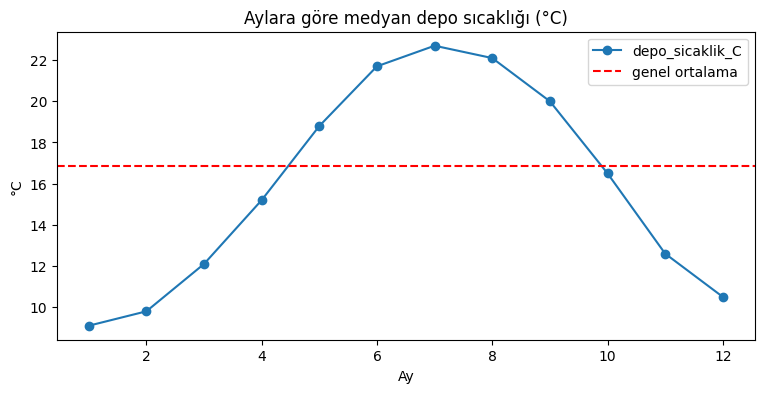

In [49]:
hatali = ~A["depo_sicaklik_C"].between(-10, 40) & A["depo_sicaklik_C"].notna()
A.loc[hatali, "depo_sicaklik_C"] = np.nan
kaydet("A", "2.3 Gürültü", "depo_sicaklik_C: −10..40 °C dışı (999,9 / 250 / 85 / −40) → NaN", hatali.sum())

aylik = A.groupby(A["tarih"].dt.month)["depo_sicaklik_C"].median()
aylik.plot(marker="o", title="Aylara göre medyan depo sıcaklığı (°C)", xlabel="Ay", ylabel="°C")
plt.axhline(A["depo_sicaklik_C"].mean(), color="red", ls="--", label="genel ortalama")
plt.legend(); plt.show()

🔍 Sıcaklık mevsime göre **9 °C ile 23 °C** arasında değişiyor. Ocak ayındaki eksik bir değere genel ortalamayı (~17 °C) yazarsak büyük hata yaparız. **Karar:** eksikleri **aynı ayın medyanı** ile dolduruyoruz (grup bazlı tahmin — basit bir regresyon gibi düşünebilirsiniz).

In [50]:
n = A["depo_sicaklik_C"].isna().sum()
A["depo_sicaklik_C"] = A["depo_sicaklik_C"].fillna(
    A.groupby(A["tarih"].dt.month)["depo_sicaklik_C"].transform("median"))
kaydet("A", "2.5 Eksik", "depo_sicaklik_C: eksikler aynı ayın medyanı ile dolduruldu", n)

✔ [A] depo_sicaklik_C: eksikler aynı ayın medyanı ile dolduruldu  →  175 satır


## 2.2–2.4 (devam) B dosyası: E-ticaret siparişleri

Aynı yöntemleri şimdi B'ye uyguluyoruz. Burada işler biraz daha hızlı ilerleyecek, çünkü yöntemi artık biliyorsunuz.

### Tarih: üç farklı dışa aktarım biçimi
Metadata'da "export tool v1 / v2" yazıyordu. Bakalım:

In [51]:
def b_bicim(x):
    s = str(x)
    if re.fullmatch(r"\d{5}", s):                             return "Excel seri no (ör. 45309)"
    if re.fullmatch(r"\d{2}/\d{2}/\d{4}", s):                 return "AA/GG/YYYY (Amerikan)"
    if re.fullmatch(r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}", s): return "YYYY-AA-GG SS:DD:SS"
    return "BİLİNMEYEN"

B["order_date"].apply(b_bicim).value_counts()

order_date
YYYY-AA-GG SS:DD:SS          1562
AA/GG/YYYY (Amerikan)         260
Excel seri no (ör. 45309)     179
Name: count, dtype: int64

📖 **Excel seri numarası:** Excel tarihleri "30 Aralık 1899'dan bu yana geçen gün sayısı" olarak saklar. `45309` → 2024-01-18.

⚠️ **Amerikan biçimi tuzağı:** `03/13/2024` → 13. ay olamayacağı için bu kesinlikle *Ay/Gün/Yıl*. Ama `03/11/2024` hem 3 Kasım hem 11 Mart olabilir! Bir sütunda **en az bir tane** 12'den büyük "ay" değeri bulursak, o sütunun biçiminin AA/GG olduğundan emin oluruz.

In [52]:
abd = B["order_date"].astype(str).str.extract(r"^(\d{2})/(\d{2})/\d{4}$").dropna().astype(int)
print("İlk parça 12'den büyük mü? ", (abd[0] > 12).any(), " → ilk parça AY olamaz mı? Hayır, olabilir.")
print("İkinci parça 12'den büyük mü?", (abd[1] > 12).any(), " → ikinci parça GÜN olmalı → biçim AA/GG/YYYY")

İlk parça 12'den büyük mü?  False  → ilk parça AY olamaz mı? Hayır, olabilir.
İkinci parça 12'den büyük mü? True  → ikinci parça GÜN olmalı → biçim AA/GG/YYYY


In [53]:
def b_tarih_coz(x):
    s = str(x)
    if re.fullmatch(r"\d{5}", s):
        return pd.Timestamp("1899-12-30") + pd.Timedelta(days=int(s))
    if "/" in s:
        return pd.to_datetime(s, format="%m/%d/%Y")
    return pd.to_datetime(s, format="%Y-%m-%d %H:%M:%S")

B["tarih"] = B["order_date"].apply(b_tarih_coz).dt.normalize()
kaydet("B", "2.2 Tutarsız", "order_date: 3 biçim (Excel no, AA/GG/YYYY, ISO) → datetime",
       (B["order_date"].apply(b_bicim) != "YYYY-AA-GG SS:DD:SS").sum())
print("Tarih aralığı:", B["tarih"].min().date(), "→", B["tarih"].max().date(), "| eksik:", B["tarih"].isna().sum())

✔ [B] order_date: 3 biçim (Excel no, AA/GG/YYYY, ISO) → datetime  →  439 satır
Tarih aralığı: 2024-01-01 → 2025-09-30 | eksik: 0


### Müşteri numarası, isim, doğum yılı

In [54]:
print("Biçime uymayan müşteri no örnekleri:", list(B.loc[~B["customer_id"].str.fullmatch(r"GMH-\d{4}"), "customer_id"].unique()[:5]))

once = B["customer_id"].copy()
B["customer_id"] = B["customer_id"].str.upper().str.replace(r"^GMH-?(\d+)$", r"GMH-\1", regex=True)
kaydet("B", "2.2 Tutarsız", "customer_id: 'gmh4148' → 'GMH-4148'", (once != B["customer_id"]).sum())

once = B["customer_name"].copy()
B["customer_name"] = B["customer_name"].apply(tr_baslik)
kaydet("B", "2.2 Tutarsız", "customer_name: büyük/küçük harf → Başlık Biçimi", (once != B["customer_name"]).sum())

B["dogum_yili"] = pd.to_datetime(B["birth_date"], errors="coerce").dt.year

Biçime uymayan müşteri no örnekleri: ['gmh5412', 'gmh5033', 'gmh7520', 'gmh6452', 'gmh5368']
✔ [B] customer_id: 'gmh4148' → 'GMH-4148'  →  274 satır
✔ [B] customer_name: büyük/küçük harf → Başlık Biçimi  →  778 satır


⚠️ B'deki bazı isimler Türkçe karakter olmadan yazılmış (`Hulya Karatas`). Bunları "düzeltmeye" çalışmayacağız; ama **varlık eşleştirmede** (Bölüm 3) `anahtar()` fonksiyonu sayesinde `Hülya Karataş` ile `Hulya Karatas` aynı anahtara düşecek.

### Şehir: `İST`, `ISTANBUL`, `istanbul`, `Deutschland`, `DE`, `NL` ...
Hem A'daki `musteri_sehir` hem B'deki `shipping_city` için **tek bir şehir sözlüğü** kullanıyoruz.

In [55]:
print(B["shipping_city"].map(anahtar).value_counts())

shipping_city
gumushane         684
istanbul          445
ankara            188
bursa             106
almanya            99
trabzon            95
kocaeli            93
izmir              51
samsun             45
erzurum            38
ist                35
antalya            23
izmit              20
trabzon/merkez     19
hollanda           17
deutschland        12
germany            10
de                  9
nl                  7
netherlands         5
Name: count, dtype: int64


In [56]:
SEHIR = {"gumushane": "Gümüşhane", "istanbul": "İstanbul", "ist": "İstanbul", "ankara": "Ankara",
         "izmir": "İzmir", "bursa": "Bursa", "kocaeli": "Kocaeli", "izmit": "Kocaeli",
         "trabzon": "Trabzon", "trabzon/merkez": "Trabzon", "samsun": "Samsun", "erzurum": "Erzurum",
         "antalya": "Antalya",
         "almanya": "Almanya", "deutschland": "Almanya", "germany": "Almanya", "de": "Almanya",
         "hollanda": "Hollanda", "netherlands": "Hollanda", "nl": "Hollanda"}

once_b, once_a = B["shipping_city"].copy(), A["musteri_sehir"].copy()
B["sehir"] = B["shipping_city"].map(anahtar).map(SEHIR)
A["musteri_sehir"] = A["musteri_sehir"].map(anahtar).map(SEHIR)
print("B'de eşlenemeyen:", list(once_b[B["sehir"].isna()].unique()), "| A'da eşlenemeyen:", list(once_a[once_a.notna() & A["musteri_sehir"].isna()].unique()))
kaydet("B", "2.2 Tutarsız", f"shipping_city: {once_b.nunique()} yazım → {B['sehir'].nunique()} şehir/ülke", (once_b != B["sehir"]).sum())
B["sehir"].value_counts()

B'de eşlenemeyen: [] | A'da eşlenemeyen: []
✔ [B] shipping_city: 36 yazım → 12 şehir/ülke  →  576 satır


sehir
Gümüşhane    684
İstanbul     480
Ankara       188
Almanya      130
Trabzon      114
Kocaeli      113
Bursa        106
İzmir         51
Samsun        45
Erzurum       38
Hollanda      29
Antalya       23
Name: count, dtype: int64

### İlçe (`shipping_district`) — Çelişen alanları **mesafe** ile çözmek 🕵️

Metadata: *"Only required for Gümüşhane deliveries"*. Ama bakın:

In [ ]:
gm_disi = B[(B["sehir"] != "Gümüşhane") & B["shipping_district"].notna()]
print(f"Gümüşhane dışı olup ilçe yazılan {len(gm_disi)} sipariş var. Örnekler:")
gm_disi[["sehir", "shipping_district", "distance_km"]].head(8)

🤔 `Samsun / Kadıköy`, `Ankara / Esenyurt`, `Almanya / Ortahisar`... Şehir mi doğru, ilçe mi?

**Üçüncü bir alan hakem olabilir:** `distance_km`. Samsun ≈ 400 km, İstanbul ≈ 1050 km. Yukarıda `Samsun / Kadıköy` satırının mesafesi 466 km → **şehir doğru, ilçe yanlış**. Bunu tüm satırlar için kontrol edelim:

In [ ]:
sehir_medyan = B.groupby("sehir")["distance_km"].median()
gm_disi = gm_disi.assign(sehrin_medyan_mesafesi=gm_disi["sehir"].map(sehir_medyan))
uyumlu = ((gm_disi["distance_km"] - gm_disi["sehrin_medyan_mesafesi"]).abs() < 100) | gm_disi["distance_km"].isna()
print(f"Mesafesi yazılan şehirle uyumlu olanlar: {uyumlu.sum()} / {len(gm_disi)}")

🔍 (Neredeyse) hepsinde mesafe **şehri** doğruluyor. **Karar:** Gümüşhane dışındaki siparişlerde ilçe bilgisi güvenilmez ve metadata'ya göre gereksiz → `NaN`.

Gümüşhane içi siparişlerde ise ilçeyi A'daki `ILCE` sözlüğüyle standartlaştırıyoruz. İlçe yerine `Gumushane` yazılmışsa? Yine mesafeye bakalım:

In [ ]:
n = B["shipping_district"].notna() & (B["sehir"] != "Gümüşhane")
B.loc[n, "shipping_district"] = np.nan
kaydet("B", "2.4 Çelişki", "Gümüşhane dışı siparişte ilçe (şehirle/mesafeyle çelişiyor) → NaN", n.sum())

B["ilce_anahtar"] = B["shipping_district"].map(anahtar)
gm = B[B["sehir"] == "Gümüşhane"]
gm.groupby("ilce_anahtar", dropna=False)["distance_km"].median().sort_values()

🔍 `gumushane` ve `gumushane merkez` yazılanların mesafesi ≈ 5 km → **Merkez**. İlçesi hiç yazılmamış (`NaN`) Gümüşhane siparişleri de var.

💡 Bunları da mesafeyle tahmin edebiliriz: her ilçenin **tipik (medyan) depo mesafesini** hesaplayıp, ilçesi eksik siparişi **en yakın** medyana sahip ilçeye atarız. (Bu, en yakın komşu sınıflandırmasının çok basit bir hâlidir.)

In [ ]:
ILCE_B = dict(ILCE, gumushane="Merkez")       # A sözlüğü + 'gumushane' → Merkez (mesafe kanıtı)
B["ilce"] = B["ilce_anahtar"].map(ILCE_B)

ilce_merkez = B.groupby("ilce")["distance_km"].median()
print("İlçelerin tipik mesafesi (km):", ilce_merkez.round().to_dict())

def en_yakin_ilce(km):
    if pd.isna(km):
        return np.nan
    return (ilce_merkez - km).abs().idxmin()

eksik_ilce = (B["sehir"] == "Gümüşhane") & B["ilce"].isna()
B.loc[eksik_ilce, "ilce"] = B.loc[eksik_ilce, "distance_km"].apply(en_yakin_ilce)
kaydet("B", "2.2 Tutarsız", "shipping_district: yazım farkları + 'Gumushane' → 6 ilçe", B["ilce_anahtar"].notna().sum())
kaydet("B", "2.5 Eksik", "Gümüşhane siparişinde eksik ilçe → en yakın tipik mesafeye göre tahmin", eksik_ilce.sum())
B = B.drop(columns="ilce_anahtar")
B.loc[B["sehir"] == "Gümüşhane", "ilce"].value_counts(dropna=False)

⚠️ Köse (≈65 km) ve Kürtün (≈70 km) birbirine yakın. Bu tahminde birkaç hata olabilir; raporda bunu **belirtmek** dürüst veri bilimidir.

### Ücretsiz kargo: 10 farklı yazım + çelişki

In [ ]:
print(B["free_shipping"].astype(str).value_counts())
EVET_HAYIR = {"true": True, "1": True, "yes": True, "evet": True,
              "false": False, "0": False, "no": False, "hayir": False}
B["ucretsiz_kargo"] = B["free_shipping"].astype(str).map(anahtar).map(EVET_HAYIR)
kaydet("B", "2.2 Tutarsız", f"free_shipping: {B['free_shipping'].astype(str).nunique()} yazım → True/False", len(B))

pd.crosstab(B["ucretsiz_kargo"], B["shipping_fee_kurus"] > 0, rownames=["ücretsiz kargo?"], colnames=["kargo ücreti > 0?"])

🔍 "Ücretsiz kargo = True" olduğu hâlde ücret alınmış (veya tersi) **çelişkili** satırlar var. Hangisi doğru? Kargo **ücreti** bir ölçüm (para), bayrak ise ondan **türetilmiş** bir bilgi. **Karar:** bayrağı ücretten yeniden üretiyoruz.

In [ ]:
yeni = B["shipping_fee_kurus"] == 0
kaydet("B", "2.4 Çelişki", "ucretsiz_kargo bayrağı kargo ücretiyle çelişiyor → ücretten türetildi", (yeni != B["ucretsiz_kargo"]).sum())
B["ucretsiz_kargo"] = yeni

### B → Gürültülü değerler: ağırlık, adet, tutar
📖 Elimizde güçlü bir alan kısıtı var: **ağırlık = adet × paket gramı** (ürün tablosundan). Bakalım tutuyor mu?

In [ ]:
B = B.merge(URUNLER[["urun_kodu", "paket_gram"]], left_on="product_sku", right_on="urun_kodu", how="left")
oran = B["weight_g"] / (B["quantity"] * B["paket_gram"])
print("ağırlık / (adet × paket gramı) oranları:")
print(oran.round(3).value_counts(dropna=False).head(8))

🔍 Oran çoğunlukla **1** (doğru). **0,001** olanlar → ağırlık **kilogram** olarak girilmiş (0,5 = 500 g). `inf` → adet 0 girilmiş. `NaN` → ağırlık eksik.

🎯 Kurallar:
1. `weight_g < 20` → kg girilmiş → ×1000
2. `quantity = 0` → adet = ağırlık ÷ paket gramı
3. `weight_g` eksik → adet × paket gramı

In [ ]:
kg = B["weight_g"] < 20
B.loc[kg, "weight_g"] *= 1000
kaydet("B", "2.3 Gürültü", "weight_g: kilogram girilmiş (<20) → ×1000", kg.sum())

sifir = B["quantity"] == 0
B.loc[sifir, "quantity"] = (B.loc[sifir, "weight_g"] / B.loc[sifir, "paket_gram"]).round()
kaydet("B", "2.3 Gürültü", "quantity = 0 (imkansız) → ağırlık ÷ paket gramı", sifir.sum())

eksik_w = B["weight_g"].isna()
B.loc[eksik_w, "weight_g"] = B.loc[eksik_w, "quantity"] * B.loc[eksik_w, "paket_gram"]
kaydet("B", "2.5 Eksik", "weight_g eksik → adet × paket gramı (alan kısıtından tahmin)", eksik_w.sum())

print("Kalan uyumsuz satır:", ((B["weight_g"] / (B["quantity"] * B["paket_gram"])).round(3) != 1).sum())

### Tutar (kuruş): bazı satırlar TL olarak girilmiş

In [ ]:
B["_birim"] = B["amount_kurus"] / B["quantity"] / 100        # TL cinsinden birim fiyat
print(B.groupby("product_sku")["_birim"].describe()[["min", "50%", "max"]].round(1))

In [ ]:
medyan = B.groupby("product_sku")["_birim"].transform("median")
tl_girilmis = B["_birim"] < medyan / 20
print(B.loc[tl_girilmis, ["product_sku", "quantity", "amount_kurus", "_birim"]].head())
B.loc[tl_girilmis, "amount_kurus"] *= 100
kaydet("B", "2.3 Gürültü", "amount_kurus: TL olarak girilmiş (medyanın 1/20'sinden küçük) → ×100", tl_girilmis.sum())
B = B.drop(columns="_birim")

### Büyük siparişler: hata mı, gerçek mi?
B'de 13–25 adetlik siparişler var ama not sütunu yok. Nasıl karar veririz? **Birim fiyat normal mi?** Eğer adet yanlış girilseydi, tutar ÷ adet = birim fiyat anormal çıkardı.

In [ ]:
B["_birim"] = B["amount_kurus"] / B["quantity"] / 100
B["_oran"] = B["_birim"] / B.groupby("product_sku")["_birim"].transform("median")
print(B.loc[B["quantity"] >= 10, ["product_sku", "quantity", "_birim", "_oran"]].round(2))
B = B.drop(columns=["_birim", "_oran"])

🔍 Birim fiyatları ürünün normal fiyatının **0,8–1,3 katı** arasında → tutar ile adet **tutarlı** → bunlar **gerçek toplu siparişler**, silinmez.

### Mesafe ve teslim süresi

In [ ]:
# Negatif mesafe imkansız ama mutlak değeri şehirle uyumluysa → eksi işareti hatası
negatif = B["distance_km"] < 0
print(B.loc[negatif, ["sehir", "distance_km"]].head())
B.loc[negatif, "distance_km"] = B.loc[negatif, "distance_km"].abs()
kaydet("B", "2.3 Gürültü", "distance_km: negatif (eksi işareti hatası) → mutlak değer", negatif.sum())

In [ ]:
# Şehrin tipik mesafesinden çok sapan değerler (ör. Ankara için 0 km)
med = B.groupby(["sehir", "ilce"], dropna=False)["distance_km"].transform("median")
sapma = (B["distance_km"] - med).abs() > (0.25 * med + 30)
print(B.loc[sapma, ["sehir", "ilce", "distance_km"]].assign(tipik=med[sapma]).head(10))
B.loc[sapma, "distance_km"] = np.nan
kaydet("B", "2.3 Gürültü", "distance_km: şehrin tipik mesafesinden çok sapıyor → NaN", sapma.sum())

n = B["distance_km"].isna().sum()
B["distance_km"] = B["distance_km"].fillna(med)
kaydet("B", "2.5 Eksik", "distance_km: eksikler aynı şehir(+ilçe) medyanı ile dolduruldu", n)

In [ ]:
print(B["delivery_days"].value_counts().sort_index())

🔍 **Negatif** gün imkansız. **0 gün** İstanbul/Almanya için imkansız (bir günde 1000+ km kargo). **45 gün** ise diğer değerlerden çok uzak (bir sonraki en büyük 12). **Kural:** `1–30` gün dışı → `NaN`.

**Eksik karar:** `delivery_days` ve `rating_10`'u **doldurmuyoruz** (gözardı). Neden? İşletmenin sorusu *"mesafe memnuniyeti etkiliyor mu?"*. Bu sütunlara ortalama yazarsak, cevaplamak istediğimiz ilişkiyi **yapay olarak zayıflatırız**. Analiz edeceğimiz hedef değişkenleri tahminle doldurmak sonucu çarpıtır.

In [ ]:
gecersiz = ~B["delivery_days"].between(1, 30) & B["delivery_days"].notna()
B.loc[gecersiz, "delivery_days"] = np.nan
kaydet("B", "2.3 Gürültü", "delivery_days: 1–30 dışı (−3, −1, 0, 45) → NaN (doldurulmadı)", gecersiz.sum())

### Tekrarlanan satırlar (B)

In [ ]:
ham_kolonlar = B_ham.columns.tolist()
tam_tekrar = B.duplicated(subset=ham_kolonlar)
print("Birebir aynı satır:", tam_tekrar.sum())
B = B[~tam_tekrar].copy()
kaydet("B", "2.6 Tekrar", "Birebir tekrar eden satırlar silindi", tam_tekrar.sum())

ayni_id = B[B["order_id"].duplicated(keep=False)].sort_values("order_id")
print("\nAynı sipariş no, farklı içerik:", ayni_id["order_id"].nunique(), "sipariş")
ayni_id[["order_id", "tarih", "customer_id", "product_sku", "quantity", "amount_kurus", "rating_10"]].head(6)

🔍 Aynı sipariş numarası, aynı müşteri, aynı ürün, aynı adet — ama tutar ≈ %10 farklı ve puan farklı. Bu, siparişin **güncellenmiş** ikinci kaydı gibi görünüyor. **Karar:** her sipariş numarasının **son** kaydını tutuyoruz (alternatif kararlar da savunulabilir; önemli olan kararı yazmak!).

In [ ]:
n = B["order_id"].duplicated(keep="last").sum()
B = B.drop_duplicates(subset="order_id", keep="last")
kaydet("B", "2.6 Tekrar", "Aynı order_id'li çelişkili kayıtlar → son kayıt tutuldu", n)
print("B'nin yeni boyutu:", B.shape)

## 2.x C dosyası: Üretici kayıtları
C küçük (26 satır) ama sorunlarla dolu. ✍️ Bu bölümü **önce kendiniz** inceleyin:

In [ ]:
C

## ✍️ Sıra Sende 4 — C'deki sorunları listeleyin
Tabloya bakarak aşağıdaki listede hangi sütunda hangi sorun olduğunu yazın. Sonra çözüm hücresini çalıştırın.

In [ ]:
c_sorunlari = {
    "uretici_kodu":       "???",   # İpucu: U05 ve U5'e bakın
    "ilce":               "???",
    "rakim_m":            "???",   # İpucu: Gümüşhane'de 12.000 m'lik bir yer var mı? Deniz seviyesinin altı?
    "organik_sertifika":  "???",
    "kurulus_yili":       "???",
    "yillik_kapasite":    "???",   # İpucu: birimlere bakın
    "kalite_sinifi":      "???",
    "ort_depo_sicakligi": "???",   # İpucu: 54,5 °C'de pestil saklanır mı?
}
c_sorunlari

<details><summary>✅ <b>Beklenen cevaplar</b></summary>

- `uretici_kodu`: **U5** satırı **U05**'in tekrarı (birebir aynı bilgiler)
- `ilce`: `KÖSE` → `Köse`
- `rakim_m`: **12000** (sıfır fazla yazılmış, imkansız), **−50** (Gümüşhane'de imkansız), bir tane **eksik**
- `organik_sertifika`: `Var/VAR/Evet/1` ve `Yok/Hayır/0` + eksik ve `?` → ikili
- `kurulus_yili`: **2031** gelecekte → imkansız
- `yillik_kapasite`: `ton`, `kg` ve birimsiz (ton) karışık → hepsi **ton**
- `kalite_sinifi`: `a/A`, `2. Sınıf`, `3. Sınıf` → `A/B/C`
- `ort_depo_sicakligi`: **54,5** ve **57,2** → Fahrenheit girilmiş! (54,5 °F ≈ 12,5 °C)
</details>

In [ ]:
# ✅ Çözüm: C temizliği
C = C.copy()

# Kod biçimi ve tekrar
C["uretici_kodu"] = C["uretici_kodu"].str.replace(r"^U(\d+)$", lambda m: f"U{int(m.group(1)):02d}", regex=True)
n = C.duplicated().sum()
C = C.drop_duplicates()
kaydet("C", "2.6 Tekrar", "U5 → U05 yapıldı; birebir tekrar silindi", n)

# İlçe
C["ilce"] = C["ilce"].map(anahtar).map(ILCE)

# Rakım: Gümüşhane için mantıklı aralık 800–2500 m; dışı → NaN → D tablosundaki ilçe rakımı
C["rakim_m"] = pd.to_numeric(C["rakim_m"], errors="coerce")
C["rakim_ham"] = C["rakim_m"]                        # Bölüm 5'te normalleştirme karşılaştırması için saklıyoruz
gecersiz = ~C["rakim_m"].between(800, 2500)
print("Geçersiz/eksik rakım:", C.loc[gecersiz, ["uretici_kodu", "ilce", "rakim_m"]].to_dict("records"))
C.loc[gecersiz, "rakim_m"] = C.loc[gecersiz, "ilce"].map(D.set_index("ilce")["yaklasik_rakim_m"])
kaydet("C", "2.3 Gürültü", "rakim_m: 12000 / −50 / eksik → D tablosundaki ilçe rakımı", gecersiz.sum())

# Organik sertifika → ikili
ORGANIK = {"var": True, "evet": True, "1": True, "yok": False, "hayir": False, "0": False}
C["organik"] = C["organik_sertifika"].map(anahtar).map(ORGANIK)
kaydet("C", "2.2 Tutarsız", "organik_sertifika: 7 yazım → True/False (eksikler NaN bırakıldı)", C["organik"].notna().sum())

# Kuruluş yılı
C["kurulus_yili"] = pd.to_numeric(C["kurulus_yili"], errors="coerce")
gelecek = C["kurulus_yili"] > 2025
C.loc[gelecek, "kurulus_yili"] = np.nan
kaydet("C", "2.3 Gürültü", "kurulus_yili: gelecekteki yıl (2031) → NaN", gelecek.sum())

# Kalite sınıfı (sıra gösteren)
KALITE = {"a": "A", "1. sinif": "A", "b": "B", "2. sinif": "B", "c": "C", "3. sinif": "C"}
C["kalite_sinifi"] = C["kalite_sinifi"].map(anahtar).map(KALITE)
kaydet("C", "2.2 Tutarsız", "kalite_sinifi: a/A/2. Sınıf/3. Sınıf → A/B/C", len(C))
C[["uretici_kodu", "ilce", "rakim_m", "organik", "kurulus_yili", "kalite_sinifi"]]

💡 Kapasitenin birimi ve sıcaklığın birimi bir *hata* değil, **farklı ölçü birimleri** sorunudur. Bunları Bölüm 3'te **değer karmaşıklığı** başlığında çözeceğiz.

---
## 2.5 Eksik veri kararları (özet)

📖 Her sütun için iki seçenek var:
- **Gözardı et:** `NaN` bırak (ya da satırı çıkar). Bilgi gerçekten yoksa ve tahmin analizi çarpıtacaksa.
- **Tahmin et:** ortalama / medyan / mod / grup bazlı / regresyon. Güvenilir bir ipucu varsa.

▶️ A dosyasında kalan eksiklere bakalım ve kararlarımızı uygulayalım:

In [ ]:
eksik = pd.DataFrame({"eksik": A.isna().sum(), "oran_%": (A.isna().mean() * 100).round(1)})
eksik[eksik["eksik"] > 0].sort_values("eksik", ascending=False)

In [ ]:
# musteri_ilce: aynı müşterinin diğer alışverişlerindeki ilçe (MOD)
n_once = A["musteri_ilce"].isna().sum()
A["musteri_ilce"] = A["musteri_ilce"].fillna(A.groupby("musteri_no")["musteri_ilce"].transform(mod))
A["musteri_sehir"] = A["musteri_sehir"].fillna(A.groupby("musteri_no")["musteri_sehir"].transform(mod))
kaydet("A", "2.5 Eksik", "musteri_ilce/sehir: aynı müşterinin diğer alışverişlerinden (mod)",
       n_once - A["musteri_ilce"].isna().sum())

# cinsiyet: aynı müşterinin diğer kayıtları (mod)
n_once = A["cinsiyet"].isna().sum()
A["cinsiyet"] = A["cinsiyet"].fillna(A.groupby("musteri_no")["cinsiyet"].transform(mod))
kaydet("A", "2.5 Eksik", "cinsiyet: aynı müşterinin diğer kayıtlarından (mod)", n_once - A["cinsiyet"].isna().sum())

# uyelik: aynı müşteri (mod)
n_once = A["uyelik"].isna().sum()
A["uyelik"] = A["uyelik"].fillna(A.groupby("musteri_no")["uyelik"].transform(mod))
kaydet("A", "2.5 Eksik", "uyelik: aynı müşterinin diğer kayıtlarından (mod)", n_once - A["uyelik"].isna().sum())

# odeme: aynı fişteki diğer satır (bir fiş tek seferde ödenir)
n_once = A["odeme"].isna().sum()
A["odeme"] = A["odeme"].fillna(A.groupby("fis_no")["odeme"].transform(mod))
kaydet("A", "2.5 Eksik", "odeme: aynı fişin diğer satırlarından", n_once - A["odeme"].isna().sum())

# Ürünü belli olmayan satır analize katılamaz → sil
n = A["urun_kodu"].isna().sum()
A = A[A["urun_kodu"].notna()].copy()
kaydet("A", "2.5 Eksik", "urun eksik → satır silindi (ürünsüz satış analiz edilemez)", n)

eksik = pd.DataFrame({"eksik": A.isna().sum(), "oran_%": (A.isna().mean() * 100).round(1)})
eksik[eksik["eksik"] > 0].sort_values("eksik", ascending=False)

### 📋 Karar tablosu

| Sütun | Karar | Gerekçe |
|---|---|---|
| `tarih` | **Tahmin** (aynı fiş) | Bir fişteki tüm satırlar aynı gün |
| `adet` | **Tahmin** (tutar ÷ fiyat) | Alan kısıtı kesin sonuç verir |
| `dogum_yili`, `yas` | **Tahmin** (müşteri modu, yıl−yaş) | Kişinin doğum yılı değişmez; kalanlar `NaN` |
| `depo_sicaklik_C` | **Tahmin** (ay medyanı) | Güçlü mevsimsellik; genel ortalama hatalı olur |
| `cinsiyet`, `uyelik`, `musteri_ilce` | **Tahmin** (müşteri modu) | Aynı kişi; kalanlar `NaN` (misafirler) |
| `odeme` | **Tahmin** (fiş modu) | Fiş tek seferde ödenir |
| `memnuniyet_5` | **Gözardı** | Hedef değişken; uydurmak analizi çarpıtır |
| `musteri_no`, `ad_soyad` | **Gözardı** | Misafir müşteri — kimlik gerçekten yok |
| `urun` | **Satırı sil** | Ürünsüz satış hiçbir soruya cevap vermez |
| B `rating_10`, `delivery_days` | **Gözardı** | Hedef değişkenler |
| B `weight_g` | **Tahmin** (adet × gram) | Alan kısıtı |
| B `distance_km` | **Tahmin** (şehir medyanı) | Mesafe şehre bağlı |
| B `gender`, `membership`, `birth_date` | **Gözardı** | Güvenilir ipucu yok |

---
## 2.6 Tekrarlanan satırlar (A)

⚠️ **Önemli ders:** Tekrar kontrolünü **standartlaştırmadan sonra** yapın! Ham veride aynı satır `05.10.2024` ve `2024-10-05` olarak yazıldığı için "farklı" görünür.

In [ ]:
print("Ham veride birebir aynı satır      :", A_ham.duplicated().sum())
print("Ham veride aynı (fis_no, satir_no) :", A_ham.duplicated(subset=["fis_no", "satir_no"]).sum())

anahtar_kol = ["fis_no", "satir_no", "tarih", "urun_kodu", "adet", "birim_fiyat_TL"]
tekrar = A.duplicated(subset=anahtar_kol)
print("Temizlenmiş veride tekrar          :", tekrar.sum())
A = A[~tekrar].copy()
kaydet("A", "2.6 Tekrar", "Tekrar eden satırlar (standartlaştırma sonrası; fiş+satır+tarih+ürün+adet+fiyat) silindi", tekrar.sum())
print("A'nın yeni boyutu:", A.shape)

🔍 Ham veride birebir tekrar sayısı, temizlenmiş verideki tekrar sayısından **az**. Aradaki fark, sadece yazım biçimi farklı olduğu için gözden kaçacak olan tekrarlardır.

---
# 3. Veri Birleştirme

Artık her dosya kendi içinde temiz. Şimdi A (dükkan) ve B (e-ticaret) satışlarını **tek tabloda** birleştireceğiz, C (üretici) ve D (ilçe) bilgilerini de ekleyeceğiz.

## 3.1 Şema birleştirme: Hangi sütun hangisine karşılık geliyor?

📖 İki sistem aynı bilgiyi **farklı isimle**, bazen **farklı anlamla** tutar. Örneğin:
- A'da `tutar_TL` **KDV hariç**, B'de `amount_kurus` **KDV dahil** (metadata: *"VAT incl."*). Doğru eşleşme: A'nın `kdv_dahil_tutar_TL` ↔ B'nin `amount_kurus`!
- B'de `weight_g` var, A'da yok → A için `adet × paket gramı` ile türetiriz.

▶️ Eşleştirme tablomuz:

In [ ]:
sema = pd.DataFrame([
    ("kaynak",          "'Dükkan' (sabit)",       "'E-ticaret' (sabit)",            "yeni sütun"),
    ("siparis_no",      "fis_no",                 "order_id",                       "metin"),
    ("tarih",           "tarih",                  "order_date",                     "datetime (Bölüm 2'de çözüldü)"),
    ("musteri_id",      "musteri_no",             "customer_id",                    "farklı sistemler! → Bölüm 3.3"),
    ("ad_soyad",        "ad_soyad",               "customer_name",                  "Başlık Biçimi"),
    ("cinsiyet",        "cinsiyet (E/K)",         "gender (M/F/1/0)",               "→ E/K"),
    ("dogum_yili",      "dogum_yili",             "birth_date",                     "B: tarihten yıl"),
    ("musteri_sehir",   "ilce (ayrıştırıldı)",    "shipping_city",                  "ortak şehir sözlüğü"),
    ("musteri_ilce",    "ilce (ayrıştırıldı)",    "shipping_district",              "6 ilçe"),
    ("urun_kodu",       "urun (eşlendi)",         "product_sku",                    "ortak ürün kodu"),
    ("adet",            "adet",                   "quantity",                       ""),
    ("agirlik_g",       "— (adet × gram)",        "weight_g",                       "A için türetildi"),
    ("tutar_TL",        "kdv_dahil_tutar_TL",     "amount_kurus",                   "KDV dahil, B: kuruş ÷ 100"),
    ("kargo_TL",        "— (0)",                  "shipping_fee_kurus",             "kuruş ÷ 100"),
    ("mesafe_km",       "— (dükkan: yok)",        "distance_km",                    ""),
    ("teslim_gun",      "— (yok)",                "delivery_days",                  ""),
    ("memnuniyet_5",    "memnuniyet (1–5)",       "rating_10 (1–10)",               "ölçek dönüşümü"),
    ("uyelik",          "uyelik (TR)",            "membership (EN)",                "Bronze→Bronz ..."),
    ("odeme",           "odeme",                  "— ('Online')",                   ""),
    ("kampanya",        "—",                      "campaign_code",                  "+ indirim oranı"),
    ("uretici_kodu",    "—",                      "producer_code (U-013)",          "C biçimi: U13"),
    ("depo_sicaklik_C", "depo_sicaklik_C",        "—",                              ""),
], columns=["ortak_sütun", "A (dükkan)", "B (e-ticaret)", "dönüşüm / not"])
sema

## 3.2 Değer karmaşıklığı: Farklı birimler ve kodlamalar

| Konu | A / C | B | Ortak biçim |
|---|---|---|---|
| Para birimi | TL | **kuruş** | TL |
| Ağırlık | – | gram (bazen kg → düzeltildi) | gram |
| Puan ölçeği | 1–5 | **1–10** | 1–5 |
| Cinsiyet | E / K | **M / F**, eski hesaplar **1 / 0** | E / K |
| Üyelik | Bronz / Gümüş / Altın | **Bronze / Silver / Gold** | Türkçe |
| Sıcaklık (C) | °C, bazen **°F** | – | °C |
| Kapasite (C) | ton, **kg**, birimsiz | – | ton |

### Puan ölçeği: 1–10 → 1–5
📖 İki ölçeğin **uçları** eşleşmeli: 1 → 1 ve 10 → 5. Doğrusal dönüşüm: $$p_5 = 1 + (p_{10} - 1) \times \frac{4}{9}$$

⚠️ Sık yapılan hata: `p10 / 2` → 1 puan 0,5'e düşer (1–5 ölçeğinde olmayan bir değer).

In [ ]:
ornek = pd.Series(range(1, 11))
pd.DataFrame({"rating_10": ornek, "yanlış: /2": ornek / 2, "doğru": (1 + (ornek - 1) * 4 / 9).round(2)}).T

In [ ]:
B["tutar_TL"] = B["amount_kurus"] / 100
B["kargo_TL"] = B["shipping_fee_kurus"] / 100
B["memnuniyet_5"] = 1 + (B["rating_10"] - 1) * 4 / 9
kaydet("B", "3.2 Değer", "kuruş → TL (amount, shipping_fee)", len(B))
kaydet("B", "3.2 Değer", "rating_10 (1–10) → memnuniyet_5 (1–5) doğrusal", B["rating_10"].notna().sum())

# Cinsiyet: metadata → 'Legacy accounts: 1 = male, 0 = female'
print("gender değerleri:", list(B["gender"].astype(str).unique()))
CINSIYET_B = {"M": "E", "F": "K", "1": "E", "0": "K", "1.0": "E", "0.0": "K"}
B["cinsiyet"] = B["gender"].astype(str).map(CINSIYET_B)
kaydet("B", "3.2 Değer", "gender M/F/1/0 → E/K", B["cinsiyet"].notna().sum())

UYELIK_B = {"Bronze": "Bronz", "Silver": "Gümüş", "Gold": "Altın"}
B["uyelik"] = B["membership"].map(UYELIK_B)
kaydet("B", "3.2 Değer", "membership EN → TR", B["uyelik"].notna().sum())

# Kampanya kodu → indirim oranı (metadata)
B["indirim_orani"] = B["campaign_code"].map({"BAYRAM10": 0.10, "YILBASI15": 0.15, "GURBET20": 0.20}).fillna(0)
B[["tutar_TL", "kargo_TL", "rating_10", "memnuniyet_5", "cinsiyet", "uyelik", "indirim_orani"]].head()

### C → Sıcaklık (°F → °C) ve kapasite (kg/ton → ton)
💡 Fahrenheit değerlerini nasıl yakalarız? Bir üretici deposunun ortalama sıcaklığı 30 °C'yi geçmez; 50–60 civarı değerler ancak °F olabilir: $$°C = (°F - 32) \times \frac{5}{9}$$

In [ ]:
C["ort_depo_sicakligi"] = tr_sayi(C["ort_depo_sicakligi"])
fahrenheit = C["ort_depo_sicakligi"] > 30
print(C.loc[fahrenheit, ["uretici_kodu", "ort_depo_sicakligi"]])
C.loc[fahrenheit, "ort_depo_sicakligi"] = ((C.loc[fahrenheit, "ort_depo_sicakligi"] - 32) * 5 / 9).round(1)
kaydet("C", "3.2 Değer", "ort_depo_sicakligi: °F girilmiş (>30) → °C", fahrenheit.sum())

def kapasite_ton(x):
    if pd.isna(x):
        return np.nan
    s = anahtar(x)
    sayi = float(re.sub(r"[^\d,]", "", s).replace(",", "."))
    if "kg" in s:
        return sayi / 1000
    return sayi                              # 'ton' ya da birimsiz → ton (değerler 4–60 aralığında)

C["kapasite_ton"] = C["yillik_kapasite"].apply(kapasite_ton)
kaydet("C", "3.2 Değer", "yillik_kapasite: kg/ton/birimsiz → ton", C["yillik_kapasite"].str.contains("kg", na=False).sum())
C[["uretici_kodu", "yillik_kapasite", "kapasite_ton", "ort_depo_sicakligi"]]

### Üretici kodlarını eşleştirme: B (`U-013`) ↔ C (`U13`)

In [ ]:
B["uretici_kodu"] = B["producer_code"].str.replace(r"^U-(\d+)$", lambda m: f"U{int(m.group(1)):02d}", regex=True)
eslesmeyen = B.loc[~B["uretici_kodu"].isin(C["uretici_kodu"]), "uretici_kodu"]
print("C'de bulunmayan üretici kodları:", eslesmeyen.value_counts().to_dict())
kaydet("B", "3.1 Şema", "producer_code 'U-013' → 'U13' biçimi; C'de olmayan kodlar NaN", len(eslesmeyen))
B.loc[~B["uretici_kodu"].isin(C["uretici_kodu"]), "uretici_kodu"] = np.nan

🔍 `U00`, `U26`, `U31`, `U99` kayıt defterinde yok. `U99` tipik bir "bilinmiyor" kodu; diğerleri kayda geçmemiş üreticiler olabilir. **Karar:** bu satırları silmiyoruz (satış gerçek), sadece üretici bilgisini `NaN` yapıyoruz.

## 3.3 A ve B'yi ortak şemaya getirip birleştirme

In [ ]:
gram = URUNLER.set_index("urun_kodu")["paket_gram"]
ad   = URUNLER.set_index("urun_kodu")["urun_adi"]

A_ortak = pd.DataFrame({
    "kaynak": "Dükkan",
    "siparis_no": A["fis_no"],
    "tarih": A["tarih"],
    "musteri_id": A["musteri_no"],
    "ad_soyad": A["ad_soyad"],
    "cinsiyet": A["cinsiyet"],
    "dogum_yili": A["dogum_yili"],
    "musteri_sehir": A["musteri_sehir"],
    "musteri_ilce": A["musteri_ilce"],
    "urun_kodu": A["urun_kodu"],
    "urun_adi": A["urun_kodu"].map(ad),
    "adet": A["adet"],
    "agirlik_g": A["adet"] * A["urun_kodu"].map(gram),
    "tutar_TL": A["kdv_dahil_tutar_TL"],
    "tutar_kdv_haric_TL": A["tutar_TL"],        # fazlalık analizi için geçici olarak tutuyoruz
    "kargo_TL": 0.0,
    "mesafe_km": np.nan,
    "teslim_gun": np.nan,
    "memnuniyet_5": A["memnuniyet_5"],
    "uyelik": A["uyelik"],
    "odeme": A["odeme"],
    "indirim_orani": 0.0,
    "uretici_kodu": np.nan,
    "depo_sicaklik_C": A["depo_sicaklik_C"],
    "misafir": A["misafir"],
    "notlar": A["notlar"],
})

B_ortak = pd.DataFrame({
    "kaynak": "E-ticaret",
    "siparis_no": B["order_id"],
    "tarih": B["tarih"],
    "musteri_id": B["customer_id"],
    "ad_soyad": B["customer_name"],
    "cinsiyet": B["cinsiyet"],
    "dogum_yili": B["dogum_yili"],
    "musteri_sehir": B["sehir"],
    "musteri_ilce": B["ilce"],
    "urun_kodu": B["product_sku"],
    "urun_adi": B["product_sku"].map(ad),
    "adet": B["quantity"],
    "agirlik_g": B["weight_g"],
    "tutar_TL": B["tutar_TL"],
    "tutar_kdv_haric_TL": B["tutar_TL"] / 1.01,
    "kargo_TL": B["kargo_TL"],
    "mesafe_km": B["distance_km"],
    "teslim_gun": B["delivery_days"],
    "memnuniyet_5": B["memnuniyet_5"],
    "uyelik": B["uyelik"],
    "odeme": "Online",
    "indirim_orani": B["indirim_orani"],
    "uretici_kodu": B["uretici_kodu"],
    "depo_sicaklik_C": np.nan,
    "misafir": False,
    "notlar": np.nan,
})

birlesik = pd.concat([A_ortak, B_ortak], ignore_index=True)
birlesik["yas"] = birlesik["tarih"].dt.year - birlesik["dogum_yili"]
kaydet("A+B", "3.3 Birleştirme", "A ve B ortak şemaya getirilip alt alta eklendi", len(birlesik))
print(birlesik.shape)
birlesik["kaynak"].value_counts()

In [ ]:
# C (üretici) ve D (ilçe) bilgilerini ekleyelim
birlesik = birlesik.merge(
    C[["uretici_kodu", "ilce", "rakim_m", "organik", "kalite_sinifi"]].rename(
        columns={"ilce": "uretici_ilce", "rakim_m": "uretici_rakim_m",
                 "organik": "uretici_organik", "kalite_sinifi": "uretici_kalite"}),
    on="uretici_kodu", how="left")

birlesik = birlesik.merge(
    D[["ilce", "bolge", "merkeze_uzaklik_km", "yaklasik_rakim_m"]].rename(
        columns={"ilce": "musteri_ilce", "bolge": "musteri_bolge",
                 "merkeze_uzaklik_km": "ilce_merkeze_uzaklik_km", "yaklasik_rakim_m": "ilce_rakim_m"}),
    on="musteri_ilce", how="left")
print(birlesik.shape)
birlesik.sample(3, random_state=1)

## 3.4 Varlık eşleştirme: Aynı müşteri iki kanalda da var mı?

📖 Dükkandaki `M-00426` ile e-ticaretteki `GMH-1234` **aynı kişi** olabilir; ama numaralar farklı sistemlerden geldiği için doğrudan eşleşmez. Ortak alanlar: **ad-soyad** ve **doğum yılı**.

⚠️ **Tuzak:** Türkiye'de aynı ad-soyada sahip çok kişi vardır ("Zeynep Keskin"). Sadece isimle eşleştirirsek **farklı kişileri birleştiririz**. İsim + doğum yılı daha güvenli bir anahtardır.

🎯 Adımlar:
1. Her kanaldaki **müşteri listesini** çıkar (bir müşteri = bir satır)
2. Eşleştirme anahtarı oluştur: `anahtar(ad_soyad)` (Türkçe karakter farkını yok eder) + `dogum_yili`
3. Sadece isimle ve isim+doğum yılıyla eşleşme sayılarını karşılaştır

In [ ]:
def musteri_listesi(df, kaynak):
    m = df[(df["kaynak"] == kaynak) & df["musteri_id"].notna()]
    return (m.groupby("musteri_id")
             .agg(ad_soyad=("ad_soyad", mod), dogum_yili=("dogum_yili", mod), sehir=("musteri_sehir", mod))
             .reset_index()
             .assign(isim_anahtar=lambda x: x["ad_soyad"].map(anahtar)))

mus_A = musteri_listesi(birlesik, "Dükkan")
mus_B = musteri_listesi(birlesik, "E-ticaret")
print("Dükkan müşterisi:", len(mus_A), "| E-ticaret müşterisi:", len(mus_B))
mus_B.head()

In [ ]:
# 1) Sadece isimle
sadece_isim = mus_A.merge(mus_B, on="isim_anahtar", suffixes=("_A", "_B"))
# 2) İsim + doğum yılı
isim_dy = mus_A.merge(mus_B, on=["isim_anahtar", "dogum_yili"], suffixes=("_A", "_B"))

print("Sadece isimle eşleşen çift         :", len(sadece_isim))
print("İsim + doğum yılı ile eşleşen çift :", len(isim_dy))
print("→ Yanlış eşleşme riski taşıyan     :", len(sadece_isim) - len(isim_dy))

In [ ]:
# Aynı isim, farklı doğum yılı = muhtemelen FARKLI kişiler. Bir örnek:
farkli = sadece_isim[sadece_isim["dogum_yili_A"] != sadece_isim["dogum_yili_B"]]
ornek_isim = farkli["isim_anahtar"].value_counts().index[0]
farkli[farkli["isim_anahtar"] == ornek_isim][["musteri_id_A", "ad_soyad_A", "dogum_yili_A", "sehir_A",
                                              "musteri_id_B", "ad_soyad_B", "dogum_yili_B", "sehir_B"]]

In [ ]:
# Ortak müşteri kimliği: eşleşenler için A numarası, diğerleri kendi numarası
eslesme = dict(zip(isim_dy["musteri_id_B"], isim_dy["musteri_id_A"]))
birlesik["ortak_musteri_id"] = birlesik["musteri_id"].replace(eslesme)
birlesik["iki_kanalli"] = birlesik["ortak_musteri_id"].isin(isim_dy["musteri_id_A"])

kaydet("A+B", "3.4 Varlık", f"İsim+doğum yılı ile {len(isim_dy)} ortak müşteri bulundu (sadece isimle {len(sadece_isim)} olurdu)",
       birlesik["iki_kanalli"].sum())
print("Her iki kanalda alışveriş yapan müşteri:", isim_dy["musteri_id_A"].nunique())

🔍 Doğum yılını eklemek, aynı isimli **farklı kişileri** ayırdı. Doğum yılı eksik olan B müşterileri eşleştirilemedi — bu bir sınırlılıktır ve raporda belirtilmelidir.

## ✍️ Sıra Sende 5 — Daha sıkı bir eşleştirme
İsim + doğum yılı + **şehir** ile eşleştirirseniz kaç çift bulursunuz? Neden daha az olabilir? (İpucu: gurbetçi bir müşteri dükkana memleketteyken gelir, e-ticaretten ise İstanbul'a sipariş verir!)

In [ ]:
# TODO: on=[...] listesine "sehir" ekleyin ve sonucu yorumlayın
# siki = mus_A.merge(mus_B, on=["isim_anahtar", "dogum_yili", ...])
# len(siki)

## 3.5 Veri fazlalığı (redundancy): Birbirinden türetilebilen sütunlar

📖 İki sütun arasında **korelasyon ≈ ±1** ise biri diğerinden türetilebilir → birini atmak bilgi kaybettirmez. Pearson korelasyonu:
$$r = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum (x_i-\bar x)^2}\sqrt{\sum (y_i-\bar y)^2}}$$

In [ ]:
sayisal = ["adet", "agirlik_g", "tutar_TL", "tutar_kdv_haric_TL", "kargo_TL", "mesafe_km",
           "teslim_gun", "memnuniyet_5", "dogum_yili", "yas", "depo_sicaklik_C"]
kor = birlesik[sayisal].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(kor, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(sayisal))); ax.set_xticklabels(sayisal, rotation=60, ha="right")
ax.set_yticks(range(len(sayisal))); ax.set_yticklabels(sayisal)
for i in range(len(sayisal)):
    for j in range(len(sayisal)):
        r = kor.iloc[i, j]
        ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(r) > 0.6 else "black")
plt.colorbar(im); plt.title("Korelasyon matrisi"); plt.tight_layout(); plt.show()

In [ ]:
# |r| > 0.95 olan çiftleri listele
ciftler = (kor.where(np.triu(np.ones(kor.shape, dtype=bool), k=1))
              .stack().rename("r").reset_index())
ciftler[ciftler["r"].abs() > 0.95].sort_values("r", key=abs, ascending=False)

🔍 **Kararlar:**

| Çift | r | Tutulan | Atılan | Neden |
|---|---|---|---|---|
| `tutar_TL` ↔ `tutar_kdv_haric_TL` | 1,00 | `tutar_TL` (KDV dahil) | KDV hariç | Tam olarak ×1,01; B zaten KDV dahil |
| `yas` ↔ `dogum_yili` | ≈ −1 | `dogum_yili` | `yas` (sonra yeniden türetilebilir) | Doğum yılı değişmez, yaş her yıl değişir |
| `adet` ↔ `agirlik_g` | yüksek | ikisi de | – | Ürüne göre gram değiştiği için tam türetilemez (ama ürün kodu + adet ile türetilebilir) |

Kategorik fazlalıklar korelasyonla görünmez ama mantıkla bulunur: `product_name` ↔ `product_sku` (1'e 1), `free_shipping` ↔ `shipping_fee == 0`, `urun_adi` ↔ `urun_kodu`.

**Tekrarlanan satırlar:** Bölüm 2.6'da her kaynakta ayrı ayrı silindi. Son kontrol:

In [ ]:
print("Birleşik veride (kaynak, siparis_no, urun_kodu, tarih, adet, tutar) tekrarı:",
      birlesik.duplicated(subset=["kaynak", "siparis_no", "urun_kodu", "tarih", "adet", "tutar_TL"]).sum())
birlesik = birlesik.drop(columns=["tutar_kdv_haric_TL"])
kaydet("A+B", "3.5 Fazlalık", "tutar_kdv_haric_TL atıldı (tutar_TL ile r = 1)", len(birlesik))

---
# 4. Veri İndirgeme

## 4.1 Veri küpü: İlçe × Ürün × Ay

📖 **Veri küpü**, bir ölçüyü (burada *satış tutarı*) birden çok **boyuta** göre özetler. Küp üzerinde:
- **Dilimleme (slice):** bir boyutu sabitle → "sadece Kelkit"
- **Toplulaştırma (roll-up):** bir boyutu üst seviyeye çık → ay → çeyrek → yıl
- **Detaya inme (drill-down):** tersi

İlçe boyutu için: Gümüşhane içindeyse 6 ilçeden biri, il dışındaysa **"İl dışı"**, bilinmiyorsa **"Bilinmiyor"**.

In [ ]:
def ilce_boyutu(r):
    if pd.notna(r["musteri_ilce"]):
        return r["musteri_ilce"]
    if pd.notna(r["musteri_sehir"]) and r["musteri_sehir"] != "Gümüşhane":
        return "İl dışı"
    return "Bilinmiyor"

birlesik["ilce_boyut"] = birlesik.apply(ilce_boyutu, axis=1)
birlesik["ay"] = birlesik["tarih"].dt.to_period("M")
birlesik["ceyrek"] = birlesik["tarih"].dt.to_period("Q")
birlesik["yil"] = birlesik["tarih"].dt.year

kup = birlesik.groupby(["ilce_boyut", "urun_adi", "ay"])["tutar_TL"].sum()
print("Küp hücre sayısı (boş olmayan):", len(kup))
kup.head(10)

In [ ]:
# Dilimleme: sadece Kelkit, ürün × çeyrek
kelkit = birlesik[birlesik["ilce_boyut"] == "Kelkit"].pivot_table(
    index="urun_adi", columns="ceyrek", values="tutar_TL", aggfunc="sum", fill_value=0)
kelkit.round(0)

In [ ]:
# Roll-up: ay → çeyrek → yıl  (ilçe × yıl)
yillik = birlesik.pivot_table(index="ilce_boyut", columns="yil", values="tutar_TL", aggfunc="sum", fill_value=0)
yillik["TOPLAM"] = yillik.sum(axis=1)
yillik.sort_values("TOPLAM", ascending=False).round(0)

In [ ]:
# Roll-up'ı görselleştirelim: aylık → çeyreklik toplam satış
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
birlesik.groupby("ay")["tutar_TL"].sum().plot(ax=ax[0], marker=".", title="Aylık satış (TL)")
birlesik.groupby("ceyrek")["tutar_TL"].sum().plot(ax=ax[1], kind="bar", title="Çeyreklik satış (TL) — roll-up")
plt.tight_layout(); plt.show()

⚠️ 2025 yalnızca Ocak–Eylül'ü kapsıyor; yıllık toplamları karşılaştırırken bunu unutmayın (2025-Q4 yok).

## ✍️ Sıra Sende 6 — Kendi dilimin
`pivot_table` ile **"Cevizli Pestil"** ürününün ilçelere göre **yıllık** satışını gösterin.

In [ ]:
# TODO
# birlesik[birlesik["urun_adi"] == "Cevizli Pestil"].pivot_table(index=..., columns=..., values="tutar_TL", aggfunc="sum")

## 4.2 Boyut indirgeme: Gereksiz özellikleri çıkarmak

In [ ]:
atilacak = {
    "musteri_id":   "ortak_musteri_id ile değiştirildi",
    "notlar":       "serbest metin; bilgisi 'toptan' ve 'gurbetci' özelliklerine aktarılacak (Bölüm 5)",
    "uretici_ilce": "sadece e-ticarette var; gerekirse uretici_kodu ile C'den her zaman geri getirilebilir",
    "ilce_merkeze_uzaklik_km": "musteri_ilce'den birebir türetilebilir (D tablosu)",
    "ilce_rakim_m": "musteri_ilce'den birebir türetilebilir (D tablosu)",
}
# Sabit sütunlar (sube, platform, export_batch), telefon, product_name, kdv hariç tutar
# zaten ortak şemaya hiç alınmadı → bu da bir boyut indirgemedir!
for k, v in atilacak.items():
    print(f"- {k:<26}: {v}")
print("\nÖnce:", birlesik.shape[1], "sütun")

💡 `notlar` sütununu atmadan önce içindeki bilgiyi özelliğe dönüştürmemiz gerekiyor; o yüzden fiziksel olarak silmeyi Bölüm 5'in sonuna bırakıyoruz.

## 4.3 Veri sıkıştırma: CSV vs gzip vs Parquet
📖
- **Kayıpsız (lossless):** dosyadan geri okuduğunuzda veri **birebir aynı**. (gzip, Parquet)
- **Kayıplı (lossy):** daha küçük ama bilgi kaybı var (ör. ondalıkları yuvarlamak, `float64` → `float16`, JPEG).

In [ ]:
import os
klasor = Path("cikti"); klasor.mkdir(exist_ok=True)
boyutlar = {}

birlesik_kayit = birlesik.copy()
birlesik_kayit["ay"] = birlesik_kayit["ay"].astype(str)
birlesik_kayit["ceyrek"] = birlesik_kayit["ceyrek"].astype(str)

birlesik_kayit.to_csv(klasor / "test.csv", index=False)
boyutlar["CSV"] = os.path.getsize(klasor / "test.csv")
birlesik_kayit.to_csv(klasor / "test.csv.gz", index=False, compression="gzip")
boyutlar["CSV + gzip"] = os.path.getsize(klasor / "test.csv.gz")
try:
    birlesik_kayit.to_parquet(klasor / "test.parquet", index=False)
    boyutlar["Parquet"] = os.path.getsize(klasor / "test.parquet")
except ImportError:
    print("⚠️ pyarrow yüklü değil → Parquet atlandı.  (!pip install pyarrow)")

# Kayıplı örnek: tutarı tam sayıya yuvarla, ondalıklı sütunları float16'ya indir
kayipli = birlesik_kayit.copy()
for c in kayipli.select_dtypes("float").columns:
    kayipli[c] = kayipli[c].round(0).astype("float16")
kayipli.to_csv(klasor / "test_kayipli.csv.gz", index=False, compression="gzip")
boyutlar["Kayıplı (yuvarlanmış) + gzip"] = os.path.getsize(klasor / "test_kayipli.csv.gz")

tablo = pd.DataFrame({"bayt": boyutlar})
tablo["KB"] = (tablo["bayt"] / 1024).round(1)
tablo["CSV'ye oran"] = (tablo["bayt"] / boyutlar["CSV"]).round(2)
tablo

In [ ]:
# Kayıpsız mı? Geri okuyup karşılaştıralım
geri = pd.read_csv(klasor / "test.csv.gz")
print("gzip → toplam tutar aynı mı?   ", np.isclose(geri["tutar_TL"].sum(), birlesik["tutar_TL"].sum()))
geri_k = pd.read_csv(klasor / "test_kayipli.csv.gz")
print("kayıplı → toplam tutar farkı (TL):", round(geri_k["tutar_TL"].sum() - birlesik["tutar_TL"].sum(), 2))
print("kayıplı → ilk 3 tutar:", geri_k["tutar_TL"].head(3).tolist(), "  orijinal:", birlesik["tutar_TL"].head(3).round(2).tolist())

🔍 gzip ve Parquet **kayıpsız** sıkıştırmadır: veri birebir geri gelir. Parquet ayrıca sütun tiplerini (tarih, sayı) saklar ve sütun bazlı sıkıştırdığı için genellikle en küçüğüdür. Yuvarlama/`float16` ise **kayıplıdır**: dosya biraz daha küçülür ama kuruşlar kaybolur ve geri getirilemez (`float16` ayrıca 2048'den büyük sayıları tam saklayamaz) → muhasebe verisi için kabul edilemez!

## 4.4 Büyük sayıların indirgenmesi: Histogram ve örnekleme

### Eşit genişlik vs eşit frekans
📖
- **Eşit genişlik** (`pd.cut`): her kutunun **aralığı** aynı (0–500, 500–1000 ...). Çarpık veride çoğu kayıt ilk kutulara yığılır.
- **Eşit frekans** (`pd.qcut`): her kutuda **aynı sayıda** kayıt. Kutu genişlikleri farklıdır.

In [ ]:
tutar = birlesik["tutar_TL"]
esit_genislik = pd.cut(tutar, bins=10)
esit_frekans = pd.qcut(tutar, q=10)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
esit_genislik.value_counts().sort_index().plot(kind="bar", ax=ax[0], title="Eşit genişlik (10 kutu)")
esit_frekans.value_counts().sort_index().plot(kind="bar", ax=ax[1], title="Eşit frekans (10 kutu)", color="orange")
for a in ax:
    a.set_ylabel("sipariş sayısı"); a.tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

🔍 Eşit genişlikte siparişlerin büyük kısmı ilk 1–2 kutuda; son kutular neredeyse boş (toptan siparişler). Eşit frekansta her kutuda ≈ %10 kayıt var ama kutu sınırları çok farklı genişlikte.

### Basit rastgele örnek vs tabakalı örnek
📖
- **Basit rastgele örnek (BRÖ):** her satırın seçilme şansı eşit.
- **Tabakalı örnek:** önce gruplara (tabakalara) ayır, **her gruptan** aynı oranda seç. Küçük gruplar örnekte kaybolmaz.

In [ ]:
bro = birlesik.sample(frac=0.10, random_state=42)
tabakali = birlesik.groupby("ilce_boyut", group_keys=False).sample(frac=0.10, random_state=42)

karsilastirma = pd.DataFrame({
    "Tüm veri (ort.)":   birlesik.groupby("ilce_boyut")["tutar_TL"].mean(),
    "BRÖ %10 (ort.)":    bro.groupby("ilce_boyut")["tutar_TL"].mean(),
    "Tabakalı %10 (ort.)": tabakali.groupby("ilce_boyut")["tutar_TL"].mean(),
    "Tüm veri (n)":      birlesik["ilce_boyut"].value_counts(),
    "BRÖ (n)":           bro["ilce_boyut"].value_counts(),
    "Tabakalı (n)":      tabakali["ilce_boyut"].value_counts(),
}).round(1)
karsilastirma.loc["GENEL"] = [birlesik["tutar_TL"].mean(), bro["tutar_TL"].mean(), tabakali["tutar_TL"].mean(),
                              len(birlesik), len(bro), len(tabakali)]
karsilastirma.round(1)

🔍 Gözlemler:
- İki örnek de **genel** ortalamayı makul tahmin eder.
- **n sütunlarına bakın:** BRÖ'de her ilçeden kaç kayıt geleceği şansa bağlıdır; tabakalı örnekte her ilçe **tam %10** ile temsil edilir. Tabakalı örnekleme küçük grupların örnekte *kaybolmamasını* garanti eder.
- Küçük ilçelerin ortalamaları ise **her iki** örnekte de oynak: 20–40 kayıtlık bir örneğe tek bir toptan sipariş girerse ortalama fırlar. Tabakalama temsili garanti eder, ama küçük örneklemin belirsizliğini ortadan kaldırmaz.

## ✍️ Sıra Sende 7
`random_state=42` yerine `random_state=7` yazıp iki örneği tekrar alın. Hangi örneğin ilçe sayıları (n) değişti, hangisininki aynı kaldı? Neden?

In [ ]:
# TODO

---
# 5. Veri Dönüştürme

## 5.1 Normalleştirme

| Yöntem | Formül | Sonuç aralığı |
|---|---|---|
| En küçük–en büyük (min-max) | $\dfrac{x - \min}{\max - \min}$ | [0, 1] |
| z-skor | $\dfrac{x - \bar x}{s}$ | ortalama 0, std 1 |
| Ondalık ölçekleme | $\dfrac{x}{10^j}$, $j$: en büyük mutlak değeri 1'in altına indiren en küçük tam sayı | (−1, 1) |

In [ ]:
def min_maks(x):
    return (x - x.min()) / (x.max() - x.min())

def z_skor(x):
    return (x - x.mean()) / x.std()

def ondalik_olcekleme(x):
    j = int(np.ceil(np.log10(x.abs().max() + 1e-9)))
    return x / (10 ** j)

for kolon in ["tutar_TL", "mesafe_km", "uretici_rakim_m"]:
    x = birlesik[kolon].dropna()
    birlesik[f"{kolon}_minmaks"] = min_maks(birlesik[kolon])
    birlesik[f"{kolon}_z"] = z_skor(birlesik[kolon])
    birlesik[f"{kolon}_ondalik"] = ondalik_olcekleme(birlesik[kolon])

birlesik.filter(regex="^(tutar_TL|mesafe_km|uretici_rakim_m)").describe().T[["min", "mean", "max", "std"]].round(3)

### Aykırı değerler min-max'i nasıl bozar?
Ham B verisindeki mesafede `99999` ve ham C'deki rakımda `12000` vardı. Bunlar temizlenmeden min-max uygulasaydık ne olurdu?

In [ ]:
ham_mesafe = B_ham["distance_km"]
temiz_mesafe = birlesik.loc[birlesik["kaynak"] == "E-ticaret", "mesafe_km"]
ham_rakim = C["rakim_ham"].dropna()
temiz_rakim = C["rakim_m"]

fig, ax = plt.subplots(2, 2, figsize=(12, 6))
min_maks(ham_mesafe).plot(kind="hist", bins=50, ax=ax[0, 0], title="Mesafe min-max — TEMİZLİK ÖNCESİ (99999 var)")
min_maks(temiz_mesafe).plot(kind="hist", bins=50, ax=ax[0, 1], title="Mesafe min-max — TEMİZLİK SONRASI", color="green")
min_maks(ham_rakim).plot(kind="hist", bins=20, ax=ax[1, 0], title="Rakım min-max — ÖNCE (12000, −50 var)")
min_maks(temiz_rakim).plot(kind="hist", bins=20, ax=ax[1, 1], title="Rakım min-max — SONRA", color="green")
plt.tight_layout(); plt.show()

print("Almanya siparişinin (≈2900 km) min-max değeri:  önce =",
      round((2900 - ham_mesafe.min()) / (ham_mesafe.max() - ham_mesafe.min()), 3),
      " sonra =", round((2900 - temiz_mesafe.min()) / (temiz_mesafe.max() - temiz_mesafe.min()), 3))

🔍 Temizlik öncesinde tek bir `99999` değeri, Almanya'ya giden siparişleri bile 0,03'e sıkıştırıyor; neredeyse **bütün veri sıfıra yığılıyor**. Min-max aykırı değerlere **çok duyarlıdır**. z-skor da etkilenir ama daha az. **Ders:** önce temizle, sonra normalleştir!

## 5.2 Genelleme (kavram hiyerarşisi)
📖 Ayrıntılı değeri daha genel bir kategoriye çıkarmak: ilçe → bölge, yaş → yaş grubu, tarih → ay → çeyrek → mevsim.

In [ ]:
# İlçe → bölge (D tablosundan, Bölüm 3'te eklendi); il dışı olanlar için:
birlesik["bolge"] = birlesik["musteri_bolge"].fillna(birlesik["ilce_boyut"])   # 'İl dışı' / 'Bilinmiyor' 

# Yaş → yaş grubu
birlesik["yas_grubu"] = pd.cut(birlesik["yas"], bins=[17, 29, 44, 59, 90],
                               labels=["18-29", "30-44", "45-59", "60+"])

# Tarih → ay adı, çeyrek, mevsim
MEVSIM = {12: "Kış", 1: "Kış", 2: "Kış", 3: "İlkbahar", 4: "İlkbahar", 5: "İlkbahar",
          6: "Yaz", 7: "Yaz", 8: "Yaz", 9: "Sonbahar", 10: "Sonbahar", 11: "Sonbahar"}
birlesik["ay_no"] = birlesik["tarih"].dt.month
birlesik["mevsim"] = birlesik["ay_no"].map(MEVSIM)

kaydet("A+B", "5.2 Genelleme", "ilçe→bölge, yaş→yaş grubu, tarih→ay/çeyrek/mevsim", len(birlesik))
print(birlesik["bolge"].value_counts(), "\n")
print(birlesik["yas_grubu"].value_counts(dropna=False).sort_index(), "\n")
print(birlesik.groupby("mevsim")["tutar_TL"].sum().sort_values(ascending=False).round(0))

## 5.3 Özellik oluşturma (feature construction)

Var olan sütunlardan **yeni ve anlamlı** sütunlar türetiyoruz:

| Yeni özellik | Tür | Nasıl? |
|---|---|---|
| `gurbetci` | ikili | Şehir Gümüşhane dışında **veya** not "Almanya'ya gidecek / yurt dışı / İstanbul'a götürülecek" |
| `kg_basina_fiyat` | oranlı | tutar ÷ (ağırlık / 1000) |
| `bayram_oncesi` | ikili | Ramazan / Kurban bayramından önceki 14 gün |
| `reel_tutar_TL` | oranlı | tutar ÷ fiyat endeksi (enflasyondan arındırma) |
| `toptan` | ikili | adet ≥ 10 veya not "toptan" |

In [ ]:
# 1) Gurbetçi
not_k = birlesik["notlar"].map(anahtar).fillna("")
gurbet_notu = not_k.str.contains("almanya|yurt disi|istanbul'a|gidecek", regex=True)
birlesik["gurbetci"] = (birlesik["musteri_sehir"].notna() & (birlesik["musteri_sehir"] != "Gümüşhane")) | gurbet_notu

# 2) Kg başına fiyat
birlesik["kg_basina_fiyat"] = (birlesik["tutar_TL"] / (birlesik["agirlik_g"] / 1000)).round(2)

# 3) Bayram öncesi (14 gün)
BAYRAMLAR = pd.to_datetime(["2024-04-10", "2024-06-16", "2025-03-30", "2025-06-06"])   # Ramazan & Kurban
def bayram_oncesi_mi(t):
    return any(pd.Timedelta(0) < (b - t) <= pd.Timedelta(days=14) for b in BAYRAMLAR)
birlesik["bayram_oncesi"] = birlesik["tarih"].apply(bayram_oncesi_mi)

# 4) Toptan
birlesik["toptan"] = (birlesik["adet"] >= 10) | not_k.str.contains("toptan")

birlesik[["gurbetci", "bayram_oncesi", "toptan"]].sum()

### Enflasyondan arındırılmış tutar 💸
📖 2024–2025'te fiyatlar her ay arttı. Ocak 2024'teki 300 TL ile Eylül 2025'teki 300 TL aynı değeri taşımaz. Resmî yol TÜİK'in TÜFE endeksini kullanmaktır; burada **verinin kendi fiyatlarından** basit bir endeks oluşturacağız:

1. Her ürünün her aydaki **medyan kg fiyatını** bul
2. Bunu ürünün **Ocak 2024** fiyatına böl → ürün endeksi (Ocak 2024 = 1,00)
3. Aynı aydaki tüm ürünlerin endekslerinin **medyanı** = o ayın fiyat endeksi
4. `reel_tutar = tutar ÷ endeks` → *"Ocak 2024 fiyatlarıyla tutar"*

In [ ]:
aylik_fiyat = birlesik[~birlesik["toptan"]].groupby(["urun_kodu", "ay"])["kg_basina_fiyat"].median().unstack()
urun_endeksi = aylik_fiyat.div(aylik_fiyat.iloc[:, 0], axis=0)        # ilk ay = 1
fiyat_endeksi = urun_endeksi.median()

fiyat_endeksi.plot(marker=".", title="Verinin kendi fiyat endeksi (Ocak 2024 = 1,00)")
plt.axhline(1, color="gray", ls=":"); plt.show()

birlesik["fiyat_endeksi"] = birlesik["ay"].map(fiyat_endeksi)
birlesik["reel_tutar_TL"] = (birlesik["tutar_TL"] / birlesik["fiyat_endeksi"]).round(2)
kaydet("A+B", "5.3 Özellik", "gurbetci, kg_basina_fiyat, bayram_oncesi, toptan, reel_tutar_TL türetildi", len(birlesik))
print(f"Fiyatlar dönem boyunca ≈ %{(fiyat_endeksi.iloc[-1] - 1) * 100:.0f} artmış.")

## ✍️ Sıra Sende 8 — Kendi özelliğini türet
Aşağıdakilerden birini (ya da kendi fikrinizi) yeni bir sütun olarak ekleyin:
- `hafta_sonu` (ikili): `birlesik["tarih"].dt.dayofweek >= 5`
- `mesafe_grubu` (sıra gösteren): `pd.cut(birlesik["mesafe_km"], [0, 50, 500, 1500, 5000], labels=[...])`
- `kampanyali` (ikili): `indirim_orani > 0`

In [ ]:
# TODO

### Son temizlik: boyut indirgeme kararlarını uygula

In [ ]:
# Normalleştirme sütunları gösterim içindi; final veri setinde tutar ve mesafe için min-max'i tutuyoruz
norm_at = [c for c in birlesik.columns if c.endswith(("_z", "_ondalik")) or c == "uretici_rakim_m_minmaks"]
once = birlesik.shape[1]
temiz = birlesik.drop(columns=list(atilacak) + norm_at + ["musteri_bolge", "yas", "fiyat_endeksi"])
temiz["ay"] = temiz["ay"].astype(str)
temiz["ceyrek"] = temiz["ceyrek"].astype(str)
kaydet("A+B", "4.2 Boyut", f"Gereksiz/türetilebilir sütunlar atıldı: {once} → {temiz.shape[1]} sütun", len(temiz))
print(temiz.columns.tolist())

---
# 6. İşletme Sahibinin Sorularına Cevap

Veriyi hazırlamamızın amacı buydu! Temiz veriyle cevaplar birkaç satır kod.

### Soru 1: Hangi ilçeden, hangi üründen, hangi ayda ne kadar satıyoruz?

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
temiz.groupby("ilce_boyut")["tutar_TL"].sum().sort_values().plot(kind="barh", ax=ax[0], title="İlçeye göre toplam satış (TL)")
temiz.groupby("urun_adi")["tutar_TL"].sum().sort_values().plot(kind="barh", ax=ax[1], title="Ürüne göre toplam satış (TL)", color="peru")
plt.tight_layout(); plt.show()

en_iyi_ay = temiz.groupby("ay_no")["reel_tutar_TL"].sum()
en_iyi_ay.plot(kind="bar", title="Ay numarasına göre reel satış (Ocak 2024 fiyatlarıyla)")
plt.show()

### Soru 2: Gurbetçi müşteriler yerel müşterilerden farklı mı davranıyor?

In [ ]:
gurbet_ozet = temiz.groupby("gurbetci").agg(
    satir=("tutar_TL", "size"),
    ort_tutar_TL=("tutar_TL", "mean"),
    ort_adet=("adet", "mean"),
    e_ticaret_payi=("kaynak", lambda s: (s == "E-ticaret").mean()),
    ort_memnuniyet=("memnuniyet_5", "mean"),
    kampanya_payi=("indirim_orani", lambda s: (s > 0).mean()),
).round(2)
gurbet_ozet.index = gurbet_ozet.index.map({False: "Yerel", True: "Gurbetçi"})
gurbet_ozet

🔍 Gurbetçilerin büyük çoğunluğu **e-ticaretten** alışveriş yapıyor ve **kampanya kodu** kullanma oranları belirgin şekilde yüksek (metadata'daki `GURBET20` kampanyasını hatırlayın). Ortalama sepet tutarı ise yerel müşterilere yakın. Peki ürün tercihleri farklı mı?

In [ ]:
# Gurbetçiler hangi ürünleri tercih ediyor? (satır yüzdesi)
pd.crosstab(temiz["urun_adi"], temiz["gurbetci"].map({False: "Yerel", True: "Gurbetçi"}), normalize="columns").mul(100).round(1)

### Soru 3: Kargo mesafesi memnuniyeti etkiliyor mu?
(Sadece e-ticaret siparişleri — dükkanda kargo yok.)

In [ ]:
et = temiz[temiz["kaynak"] == "E-ticaret"].copy()
et["mesafe_grubu"] = pd.cut(et["mesafe_km"], [-1, 50, 500, 1500, 5000],
                            labels=["Gümüşhane içi (<50)", "Yakın (50–500)", "Uzak (500–1500)", "Yurt dışı (>1500)"])
ozet = et.groupby("mesafe_grubu", observed=True).agg(
    siparis=("memnuniyet_5", "size"), puanli=("memnuniyet_5", "count"),
    ort_memnuniyet=("memnuniyet_5", "mean"), ort_teslim_gun=("teslim_gun", "mean")).round(2)
print(ozet, "\n")
print("Korelasyon  mesafe ↔ memnuniyet :", round(et["mesafe_km"].corr(et["memnuniyet_5"]), 3))
print("Korelasyon  teslim ↔ memnuniyet :", round(et["teslim_gun"].corr(et["memnuniyet_5"]), 3))
print("Korelasyon  mesafe ↔ teslim     :", round(et["mesafe_km"].corr(et["teslim_gun"]), 3))

🔍 Türkiye içinde (Gümüşhane, yakın ve uzak şehirler) ortalama memnuniyet neredeyse aynı; belirgin düşüş **yurt dışı** siparişlerinde, yani teslim süresinin 8–9 güne çıktığı yerde. Mesafe ile teslim süresi arasındaki korelasyon çok yüksek.

**Yorumlarken dikkat:** Korelasyon nedensellik değildir. Mesafe → teslim süresi → memnuniyet şeklinde **dolaylı** bir zincir olabilir. Ayrıca puan vermeyen müşterileri (NaN) doldurmadığımız için sonuç sadece puan veren müşterileri yansıtır — raporda bunu belirtin.

---
# 7. Rapor ve Teslim

## 7.1 İşlem raporu
Defter boyunca `kaydet()` ile tuttuğumuz kayıtlar:

In [ ]:
rapor_df = pd.DataFrame(rapor)
pd.set_option("display.max_colwidth", 120)
rapor_df

In [ ]:
# Son kontroller (assert = "bu doğru olmalı, değilse hata ver")
assert temiz["tarih"].notna().all(), "Eksik tarih var!"
assert (temiz["adet"] > 0).all(), "Adet ≤ 0 var!"
assert temiz["urun_kodu"].notna().all(), "Ürünü bilinmeyen satır var!"
assert temiz["tarih"].between("2024-01-01", "2025-09-30").all(), "Dönem dışı tarih var!"
assert temiz["yas_grubu"].dropna().isin(["18-29", "30-44", "45-59", "60+"]).all()
print("✅ Tüm kontroller geçti!")
print("Final veri seti:", temiz.shape)

In [ ]:
temiz.to_csv(klasor / "gumushane_temiz_veriseti.csv", index=False, encoding="utf-8-sig")
rapor_df.to_csv(klasor / "temizleme_raporu.csv", index=False, encoding="utf-8-sig")
for f in ["test.csv", "test.csv.gz", "test.parquet", "test_kayipli.csv.gz"]:
    (klasor / f).unlink(missing_ok=True)
print("Kaydedildi:", [f.name for f in klasor.iterdir()])

## 7.2 Teslim kontrol listesi ✅

- [ ] Her sütunun ölçek türü belirlendi (Bölüm 1)
- [ ] Eksik veri kodları sayıldı, her sütun için **gözardı / tahmin** kararı gerekçelendirildi (2.1, 2.5)
- [ ] Yazım farklılıkları tek biçime indirildi (2.2)
- [ ] İmkansız değerler ile gerçek ama sıra dışı değerler ayırt edildi (2.3)
- [ ] Çelişen alanlar alan kısıtlarıyla düzeltildi (2.4)
- [ ] Tekrarlar silindi (2.6)
- [ ] Şema eşleştirme, değer karmaşıklığı, varlık eşleştirme, fazlalık (3)
- [ ] Veri küpü + roll-up, boyut indirgeme, sıkıştırma, histogram, örnekleme (4)
- [ ] Normalleştirme (önce/sonra), genelleme, ≥ 4 yeni özellik (5)
- [ ] `cikti/gumushane_temiz_veriseti.csv` ve `cikti/temizleme_raporu.csv`

## 🧠 Kendinizi test edin
1. B'de `rating_10 = 0` olan satırlara neden ortalama puan yazmadık?
2. A'da `adet = 24` olan bir satırı neden silmedik, `adet = 999` olanı neden düzelttik?
3. Tekrar kontrolünü standartlaştırmadan **önce** yapsaydık ne olurdu?
4. Sadece isimle müşteri eşleştirseydik ne tür bir hata yapardık?
5. Min-max normalleştirmeyi aykırı değerleri temizlemeden yapmak neden kötü bir fikirdir?
6. Sıcaklık neden *aralıklı*, ağırlık neden *oranlı* ölçektir?

🎉 **Tebrikler!** Üç dağınık kaynaktan analize hazır, belgelenmiş tek bir veri seti ürettiniz.